# Bivariate Moran's I across age and replicates

Runs the screen from `09` on all 4 sections (8 and 13 months, 2 replicates each), with a separate spatial graph per section (bandwidth 400, as in `09`). n = 2 sections per age.

## Imports

In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import liana as li
import matplotlib.pyplot as plt

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning:

Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning:

Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning:

Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning:

Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning:

Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.

/home/vkorob/miniconda3/envs/lia

## Load the export and define sections

`section_id` = `time` x `replicate`; the cross-tab should show 4 sections, 2 per age.

In [2]:
import os
export_dir = "output/08_STARmapPLUS_CCC_GenePanelCheck/starmap_hpc_export"   # written by 08_STARmapPLUS_CCC_GenePanelCheck.qmd
out_dir    = "output/10_STARmapPLUS_BivariateMoransI_AgeComparison"
os.makedirs(out_dir, exist_ok=True)

expr = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T  # genes x cells -> cells x genes for AnnData

genes = pd.read_csv(f"{export_dir}/genes.txt", header=None)[0].astype(str).tolist()
cells = pd.read_csv(f"{export_dir}/cells.txt", header=None)[0].astype(str).tolist()

coords = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[cells]
meta   = pd.read_csv(f"{export_dir}/metadata.csv").set_index("cell_id").loc[cells]

adata = ad.AnnData(X=expr, obs=meta, var=pd.DataFrame(index=genes))
adata.obsm["spatial"] = coords[["spatial_1", "spatial_2"]].to_numpy()

print("adata.obs columns:", adata.obs.columns.tolist())

# ---- EDIT if these aren't the right column names in your object ----
time_col = "time"
replicate_col = "replicate"

missing = [c for c in (time_col, replicate_col) if c not in adata.obs.columns]
if missing:
    raise RuntimeError(
        f"Missing expected column(s): {missing}. "
        f"Set time_col/replicate_col above to the columns that actually identify age and replicate. "
        f"Columns present: {adata.obs.columns.tolist()}"
    )

age_col = time_col
adata.obs["section_id"] = adata.obs[time_col].astype(str) + "_" + adata.obs[replicate_col].astype(str)
sample_col = "section_id"

print(f"age_col = '{age_col}', values: {sorted(adata.obs[age_col].astype(str).unique().tolist())}")
print(f"sample_col = '{sample_col}' (built from '{time_col}' x '{replicate_col}'), values: {sorted(adata.obs[sample_col].unique().tolist())}")
print(adata.obs.groupby([age_col, sample_col], observed=True).size())

adata.obs columns: ['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'NAME', 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'sex', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'orig_index', 'batch', 'time', 'group', 'replicate', 'label', 'region', 'region_merged', 'top_level_cell_type', 'sub_level_cell_type', 'celltype_merged', 'section_id']
age_col = 'time', values: ['13months', '8months']
sample_col = 'section_id' (built from 'time' x 'replicate'), values: ['13months_replicate_1', '13months_replicate_2', '8months_replicate_1', '8months_replicate_2']
time      section_id          
13months  13months_replicate_1    3901
          13months_replicate_2    4602
8months   8months_replicate_1     3700
          8months_replicate_2     4075
dtype: int64


## Spatial graph + bivariate Moran's I per section

In [3]:
bandwidth = 400  # same choice calibrated in 09 -- revisit per-section if cell density looks very different

lr_pairs = pd.read_csv(f"{export_dir}/lr_pairs.csv")
interactions = list(zip(lr_pairs["ligand_complex"], lr_pairs["receptor_complex"]))

per_sample = {}

for sample_id in sorted(adata.obs[sample_col].unique()):
    print(f"--- {sample_id} ---")
    adata_s = adata[adata.obs[sample_col] == sample_id].copy()

    li.ut.spatial_neighbors(adata_s, bandwidth=bandwidth, kernel="gaussian", set_diag=True)

    bivar_s = li.mt.bivariate(
        adata_s,
        resource_name=None,
        interactions=interactions,
        global_name="morans",
        local_name="morans",
        connectivity_key="spatial_connectivities",
        n_perms=200,
        mask_negatives=False,   # whether to mask LowLow/NegativeNegative interactions
        add_categories=True,    # whether to add local categories to the results
        nz_prop=0,
        seed=1337,
        use_raw=False,
        verbose=False,
    )

    age_val = adata_s.obs[age_col].iloc[0]
    per_sample[sample_id] = {
        "adata": adata_s,
        "bivar_adata": bivar_s,
        "age": age_val,
        "n_cells": adata_s.n_obs,
    }
    print(f"  {adata_s.n_obs} cells, age={age_val}")

--- 13months_replicate_1 ---


  3901 cells, age=13months
--- 13months_replicate_2 ---


  4602 cells, age=13months
--- 8months_replicate_1 ---


  3700 cells, age=8months
--- 8months_replicate_2 ---


  4075 cells, age=8months


## One table across all 4 sections

One row per (pair, section).

In [4]:
score_col = None
pval_col = None

records = []
for sample_id, res in per_sample.items():
    g = res["bivar_adata"].var.copy()
    if score_col is None:
        score_col = next((c for c in g.columns if "morans" in c.lower() and "pval" not in c.lower()), None)
        pval_col  = next((c for c in g.columns if "pval" in c.lower()), None)
        if score_col is None:
            raise RuntimeError(f"Could not find a Moran's I score column. Columns present: {g.columns.tolist()}")
    g = g.reset_index().rename(columns={"index": "pair_id"})
    g["sample"] = sample_id
    g["age"] = res["age"]
    g["pair_label"] = g["ligand"].astype(str) + " -> " + g["receptor"].astype(str)
    records.append(g)

all_scores = pd.concat(records, ignore_index=True)
n_pairs = all_scores["pair_label"].nunique()
n_samples = all_scores["sample"].nunique()
print(f"{n_pairs} unique pairs x {n_samples} samples = {len(all_scores)} rows")
all_scores.head()

13 unique pairs x 4 samples = 52 rows


,interaction,ligand,receptor,ligand_means,ligand_props,receptor_means,receptor_props,morans,morans_pvals,mean,std,sample,age,pair_label
0,Calm1^Ptpra,Calm1,Ptpra,2.805595,0.645219,0.445960,0.117918,0.020601,0.00,0.041347,0.412887,13months_replicate_1,13months,Calm1 -> Ptpra
1,Efnb2^Grm5,Efnb2,Grm5,0.010269,0.002820,0.053670,0.014612,0.000004,1.00,-0.000378,0.112144,13months_replicate_1,13months,Efnb2 -> Grm5
2,Fgfr3^Epha4,Fgfr3,Epha4,0.296745,0.074596,0.429501,0.115868,-0.006949,0.00,-0.013981,0.243999,13months_replicate_1,13months,Fgfr3 -> Epha4
3,Pdgfa^Pdgfra,Pdgfa,Pdgfra,0.462509,0.123302,0.098425,0.024609,0.003451,0.10,0.007313,0.190419,13months_replicate_1,13months,Pdgfa -> Pdgfra
4,Adam10^Notch2,Adam10,Notch2,0.241387,0.062804,0.406531,0.101000,0.004773,0.02,0.009420,0.201157,13months_replicate_1,13months,Adam10 -> Notch2


## Reproducibility and age shift

1. **Reproducible within an age:** both replicates have the same sign (both positive or both negative). `min_abs_score` sets an optional zone around 0.
2. **Clean age separation:** both sections of one age lie strictly above (or below) both sections of the other; otherwise `intermixed`.

`classification` answers (1); `shift_direction` / `trustworthy_shift` answer (2).

In [5]:
import re

min_abs_score = 0.0 

def sign_label(x):
    if x > min_abs_score:
        return "positive"
    if x < -min_abs_score:
        return "negative"
    return "zero"

all_scores["sign"] = all_scores[score_col].apply(sign_label)

# how big are the scores actually driving a sign call? -- useful for picking min_abs_score
nonzero_scores = all_scores.loc[all_scores["sign"] != "zero", score_col]
print(f"Score distribution among non-'zero' rows (n={len(nonzero_scores)}): "
      f"min={nonzero_scores.min():.4f}, median={nonzero_scores.median():.4f}, max={nonzero_scores.max():.4f}")

# --- 1) within an age group: both replicates on the same side of zero ---
def group_sign_consistency(signs):
    signs = set(signs)
    if signs == {"positive"}: return "positive"
    if signs == {"negative"}: return "negative"
    return "inconsistent"

sign_per_group = (
    all_scores.groupby(["pair_label", "age"], observed=True)["sign"]
    .apply(group_sign_consistency)
    .unstack(fill_value="inconsistent")
)

def extract_months(age_str):
    """Sort age labels by the number they contain (8 before 13), not lexicographically --
    plain sorted() on strings like '8months'/'13months' would put '13months' first
    ('1' < '8' as characters), silently swapping which group gets called young vs. old."""
    m = re.search(r"\d+", str(age_str))
    return int(m.group()) if m else float("inf")

ages = sorted(all_scores["age"].unique(), key=extract_months)
if len(ages) != 2:
    print(f"Expected exactly 2 age groups, found {ages} -- adjust the young/old classification below to match.")

young_age, old_age = ages[0], ages[1]  # ---- EDIT if this pairing looks wrong for your age labels ----
print(f"Treating '{young_age}' as young_age and '{old_age}' as old_age below.")

sign_per_group = sign_per_group.rename(columns={young_age: "sign_young", old_age: "sign_old"})
sign_per_group["reproducible_young"] = sign_per_group["sign_young"] != "inconsistent"
sign_per_group["reproducible_old"] = sign_per_group["sign_old"] != "inconsistent"

def classify(row):
    y, o = row["reproducible_young"], row["reproducible_old"]
    if y and o: return "both"
    if y: return "young_only"
    if o: return "old_only"
    return "neither"

sign_per_group["classification"] = sign_per_group.apply(classify, axis=1)
print("\nWithin-group reproducibility (both replicates same sign, positive-positive OR negative-negative):")
print(sign_per_group["classification"].value_counts())

# --- 2) across ages: all sections of one age above (or below) all sections of the other ---
group_range = (
    all_scores.groupby(["pair_label", "age"], observed=True)[score_col]
    .agg(["min", "max"])
    .unstack("age")
)
group_range.columns = [f"{stat}_{age}" for stat, age in group_range.columns]

def classify_shift(row):
    if row[f"min_{old_age}"] > row[f"max_{young_age}"]:
        return "increase_with_age"
    if row[f"max_{old_age}"] < row[f"min_{young_age}"]:
        return "decrease_with_age"
    return "intermixed"

shift_per_pair = group_range.apply(classify_shift, axis=1)
shift_per_pair.name = "shift_direction"

print("\nAge-shift consistency (ALL scores of one age group clearly separated from ALL scores of the other):")
print(shift_per_pair.value_counts())

hits_per_group = sign_per_group.join(shift_per_pair)
hits_per_group["trustworthy_shift"] = hits_per_group["shift_direction"] != "intermixed"
hits_per_group.sort_values(["classification", "shift_direction"])

Score distribution among non-'zero' rows (n=52): min=-0.0120, median=0.0001, max=0.0587
Treating '8months' as young_age and '13months' as old_age below.

Within-group reproducibility (both replicates same sign, positive-positive OR negative-negative):
classification
both          8
young_only    3
old_only      2
Name: count, dtype: int64

Age-shift consistency (ALL scores of one age group clearly separated from ALL scores of the other):
shift_direction
increase_with_age    6
intermixed           5
decrease_with_age    2
Name: count, dtype: int64


,sign_old,sign_young,reproducible_young,reproducible_old,classification,shift_direction,trustworthy_shift
pair_label,,,,,,,
Calm1 -> Ptpra,positive,positive,True,True,both,decrease_with_age,True
Adam10 -> Notch2,positive,negative,True,True,both,increase_with_age,True
Apoe -> Sorl1,positive,negative,True,True,both,increase_with_age,True
Cd14 -> Itgb1,positive,negative,True,True,both,increase_with_age,True
Pdgfa -> Pdgfra,positive,negative,True,True,both,increase_with_age,True
Bsg -> Slc16a7,negative,negative,True,True,both,intermixed,False
Efnb2 -> Grm5,positive,positive,True,True,both,intermixed,False
Fgfr3 -> Epha4,negative,negative,True,True,both,intermixed,False
Igfbpl1 -> Dcc,positive,inconsistent,False,True,old_only,increase_with_age,True


## Scores per section

Global Moran's I in each of the 4 sections for pairs reproducible in at least one age; "(intermixed)" = age groups overlap.

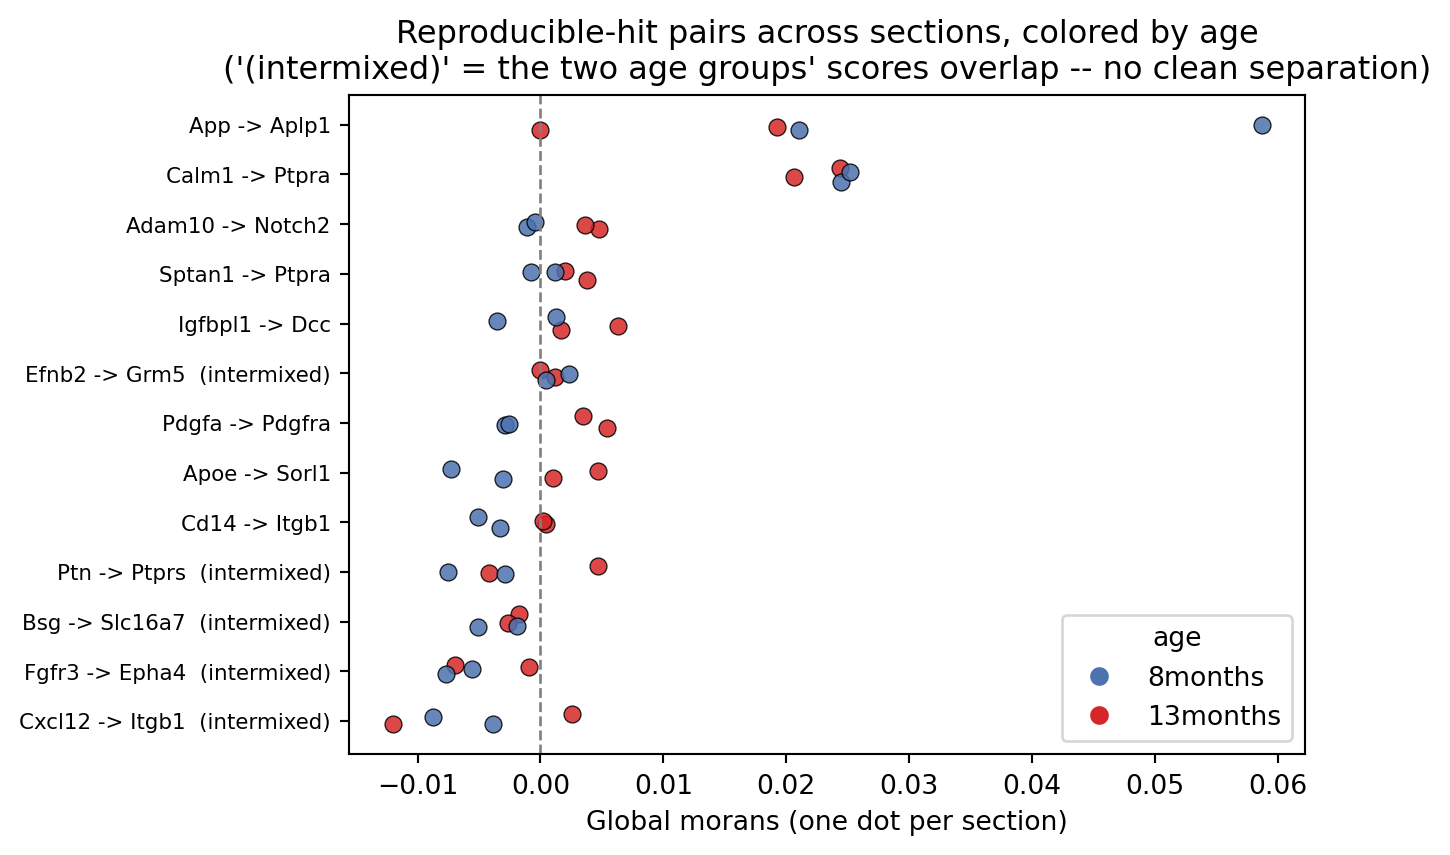

In [6]:
plot_pairs = hits_per_group[hits_per_group["classification"] != "neither"].index.tolist()
plot_data = all_scores[all_scores["pair_label"].isin(plot_pairs)].copy()

rng = np.random.default_rng(0)

pair_order = (
    plot_data.groupby("pair_label", observed=True)[score_col].mean().sort_values(ascending=False).index.tolist()
)
pair_y = {p: i for i, p in enumerate(pair_order)}
colors = {young_age: "#4c72b0", old_age: "#d62728"}

fig, ax = plt.subplots(figsize=(7, max(4, 0.35 * len(pair_order))))

for _, row in plot_data.iterrows():
    y = pair_y[row["pair_label"]] + rng.uniform(-0.15, 0.15)
    ax.scatter(row[score_col], y, color=colors.get(row["age"], "#999999"), s=40, alpha=0.85,
               edgecolors="black", linewidths=0.5)

ax.set_yticks(range(len(pair_order)))
# mark pairs whose age groups overlap
ytick_labels = [
    f"{p}  (intermixed)" if not hits_per_group.loc[p, "trustworthy_shift"] else p
    for p in pair_order
]
ax.set_yticklabels(ytick_labels, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel(f"Global {score_col} (one dot per section)")
ax.set_title("Reproducible-hit pairs across sections, colored by age\n('(intermixed)' = the two age groups' scores overlap -- no clean separation)")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=a)
           for a, c in colors.items()]
ax.legend(handles=handles, title="age", loc="lower right")
plt.tight_layout()
plt.show()

## Mean score, young vs old

Off-diagonal = age-dependent change. Pairs whose sections overlap between ages (`intermixed`) are drawn as `x` and shouldn't be read as real shifts.

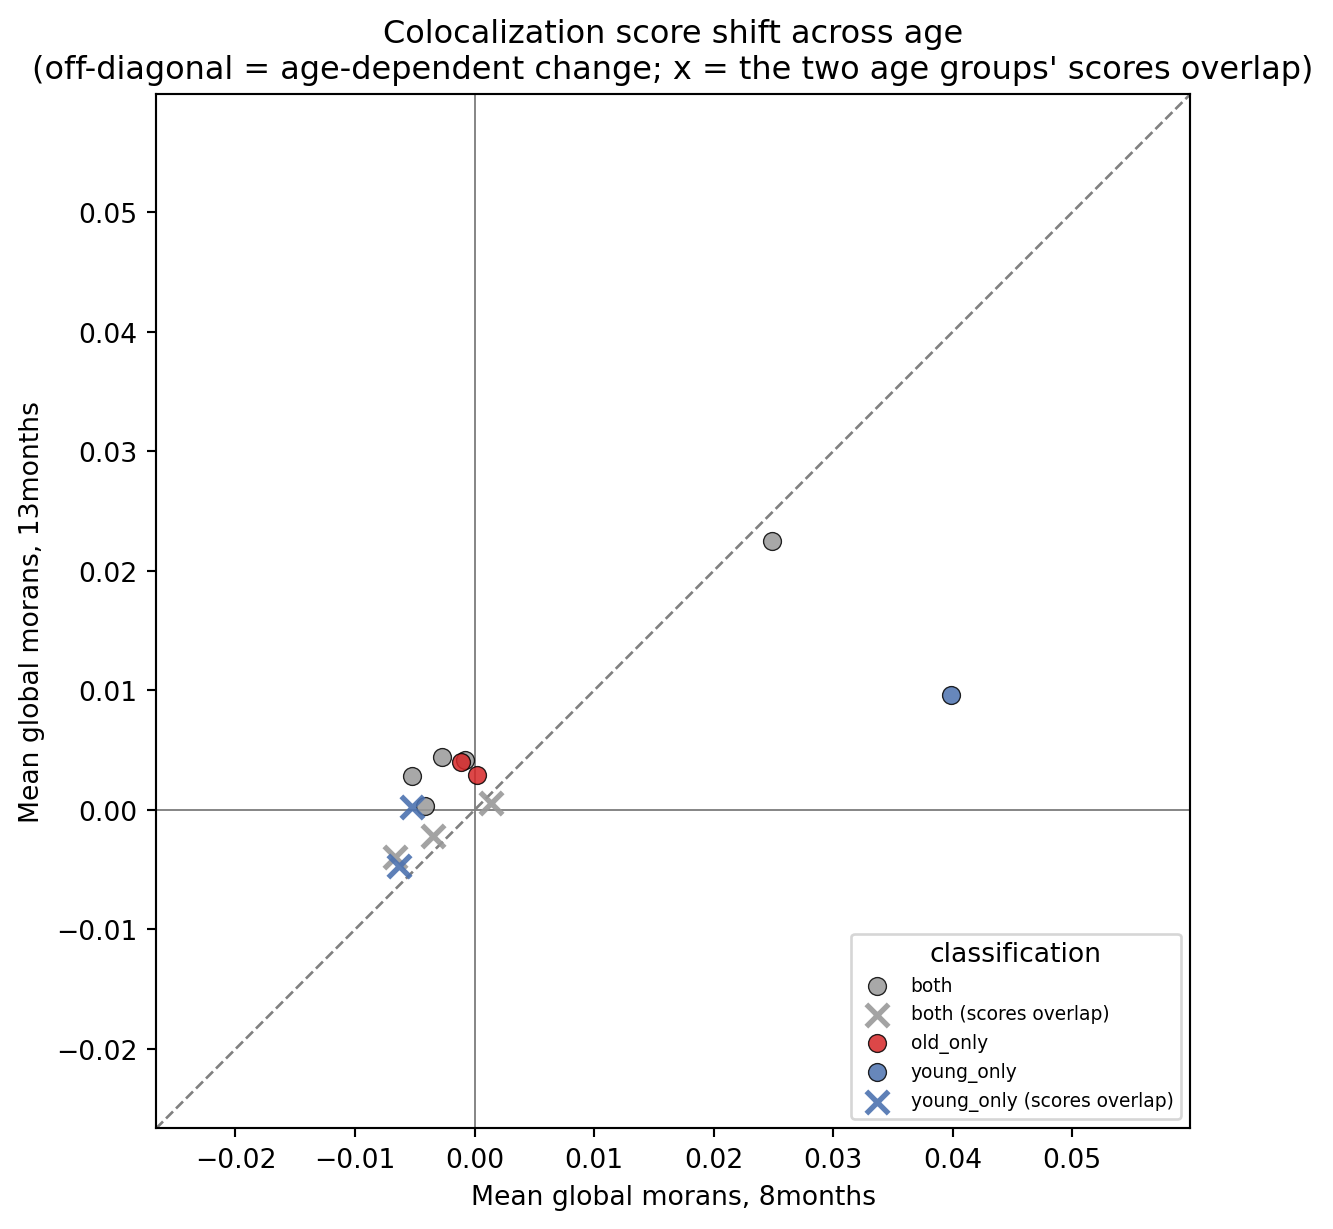

2/5 switch candidate(s) have overlapping raw scores between the two age groups (trustworthy_shift == False) -- treat those as noisy, not a real age-dependent switch.


,pair_label,classification,mean_young,mean_old,delta,shift_direction,trustworthy_shift
2,App -> Aplp1,young_only,0.039868,0.009618,-0.030249,decrease_with_age,True
11,Ptn -> Ptprs,young_only,-0.005220,0.000250,0.005469,intermixed,False
9,Igfbpl1 -> Dcc,old_only,-0.001136,0.003991,0.005127,increase_with_age,True
12,Sptan1 -> Ptpra,old_only,0.000202,0.002907,0.002705,increase_with_age,True
6,Cxcl12 -> Itgb1,young_only,-0.006317,-0.004730,0.001587,intermixed,False


In [7]:
pair_means = (
    all_scores.groupby(["pair_label", "age"], observed=True)[score_col]
    .mean()
    .unstack("age")
    .rename(columns={young_age: "mean_young", old_age: "mean_old"})
)

shift_df = pair_means.join(hits_per_group[["classification", "shift_direction", "trustworthy_shift"]]).reset_index()
shift_df["delta"] = shift_df["mean_old"] - shift_df["mean_young"]

# pairs reproducible in at least one age
plot_shift = shift_df[shift_df["classification"] != "neither"].copy()

class_colors = {"both": "#999999", "young_only": "#4c72b0", "old_only": "#d62728"}

fig, ax = plt.subplots(figsize=(6.5, 6.5))

for cls, sub in plot_shift.groupby("classification", observed=True):
    trust_sub = sub[sub["trustworthy_shift"]]
    untrust_sub = sub[~sub["trustworthy_shift"]]
    ax.scatter(trust_sub["mean_young"], trust_sub["mean_old"], color=class_colors.get(cls, "black"),
               s=45, alpha=0.85, edgecolors="black", linewidths=0.5, label=cls, zorder=3)
    if len(untrust_sub):
        ax.scatter(untrust_sub["mean_young"], untrust_sub["mean_old"], color=class_colors.get(cls, "black"),
                   marker="x", s=70, linewidths=2, alpha=0.9, zorder=4,
                   label=f"{cls} (scores overlap)")

lo = min(plot_shift["mean_young"].min(), plot_shift["mean_old"].min(), 0) - 0.02
hi = max(plot_shift["mean_young"].max(), plot_shift["mean_old"].max(), 0) + 0.02

ax.plot([lo, hi], [lo, hi], color="grey", linestyle="--", linewidth=1, zorder=1)
ax.axhline(0, color="grey", linewidth=0.7, zorder=0)
ax.axvline(0, color="grey", linewidth=0.7, zorder=0)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel(f"Mean global {score_col}, {young_age}")
ax.set_ylabel(f"Mean global {score_col}, {old_age}")
ax.set_title("Colocalization score shift across age\n(off-diagonal = age-dependent change; x = the two age groups' scores overlap)")
ax.legend(title="classification", loc="best", fontsize=7)
plt.tight_layout()
plt.show()

switch_candidates = shift_df[shift_df["classification"].isin(["young_only", "old_only"])].copy()
switch_candidates = switch_candidates.reindex(
    switch_candidates["delta"].abs().sort_values(ascending=False).index
)

n_untrustworthy = (~switch_candidates["trustworthy_shift"]).sum()
if n_untrustworthy:
    print(f"{n_untrustworthy}/{len(switch_candidates)} switch candidate(s) have overlapping raw scores between the "
          f"two age groups (trustworthy_shift == False) -- treat those as noisy, not a real age-dependent switch.")

switch_candidates[["pair_label", "classification", "mean_young", "mean_old", "delta", "shift_direction", "trustworthy_shift"]]

## Expression per cell type and section (non-intermixed pairs)

Checks whether a spatial-score shift goes with a change in the genes' expression.

8 non-intermixed pair(s): ['Adam10 -> Notch2', 'Apoe -> Sorl1', 'App -> Aplp1', 'Calm1 -> Ptpra', 'Cd14 -> Itgb1', 'Igfbpl1 -> Dcc', 'Pdgfa -> Pdgfra', 'Sptan1 -> Ptpra']


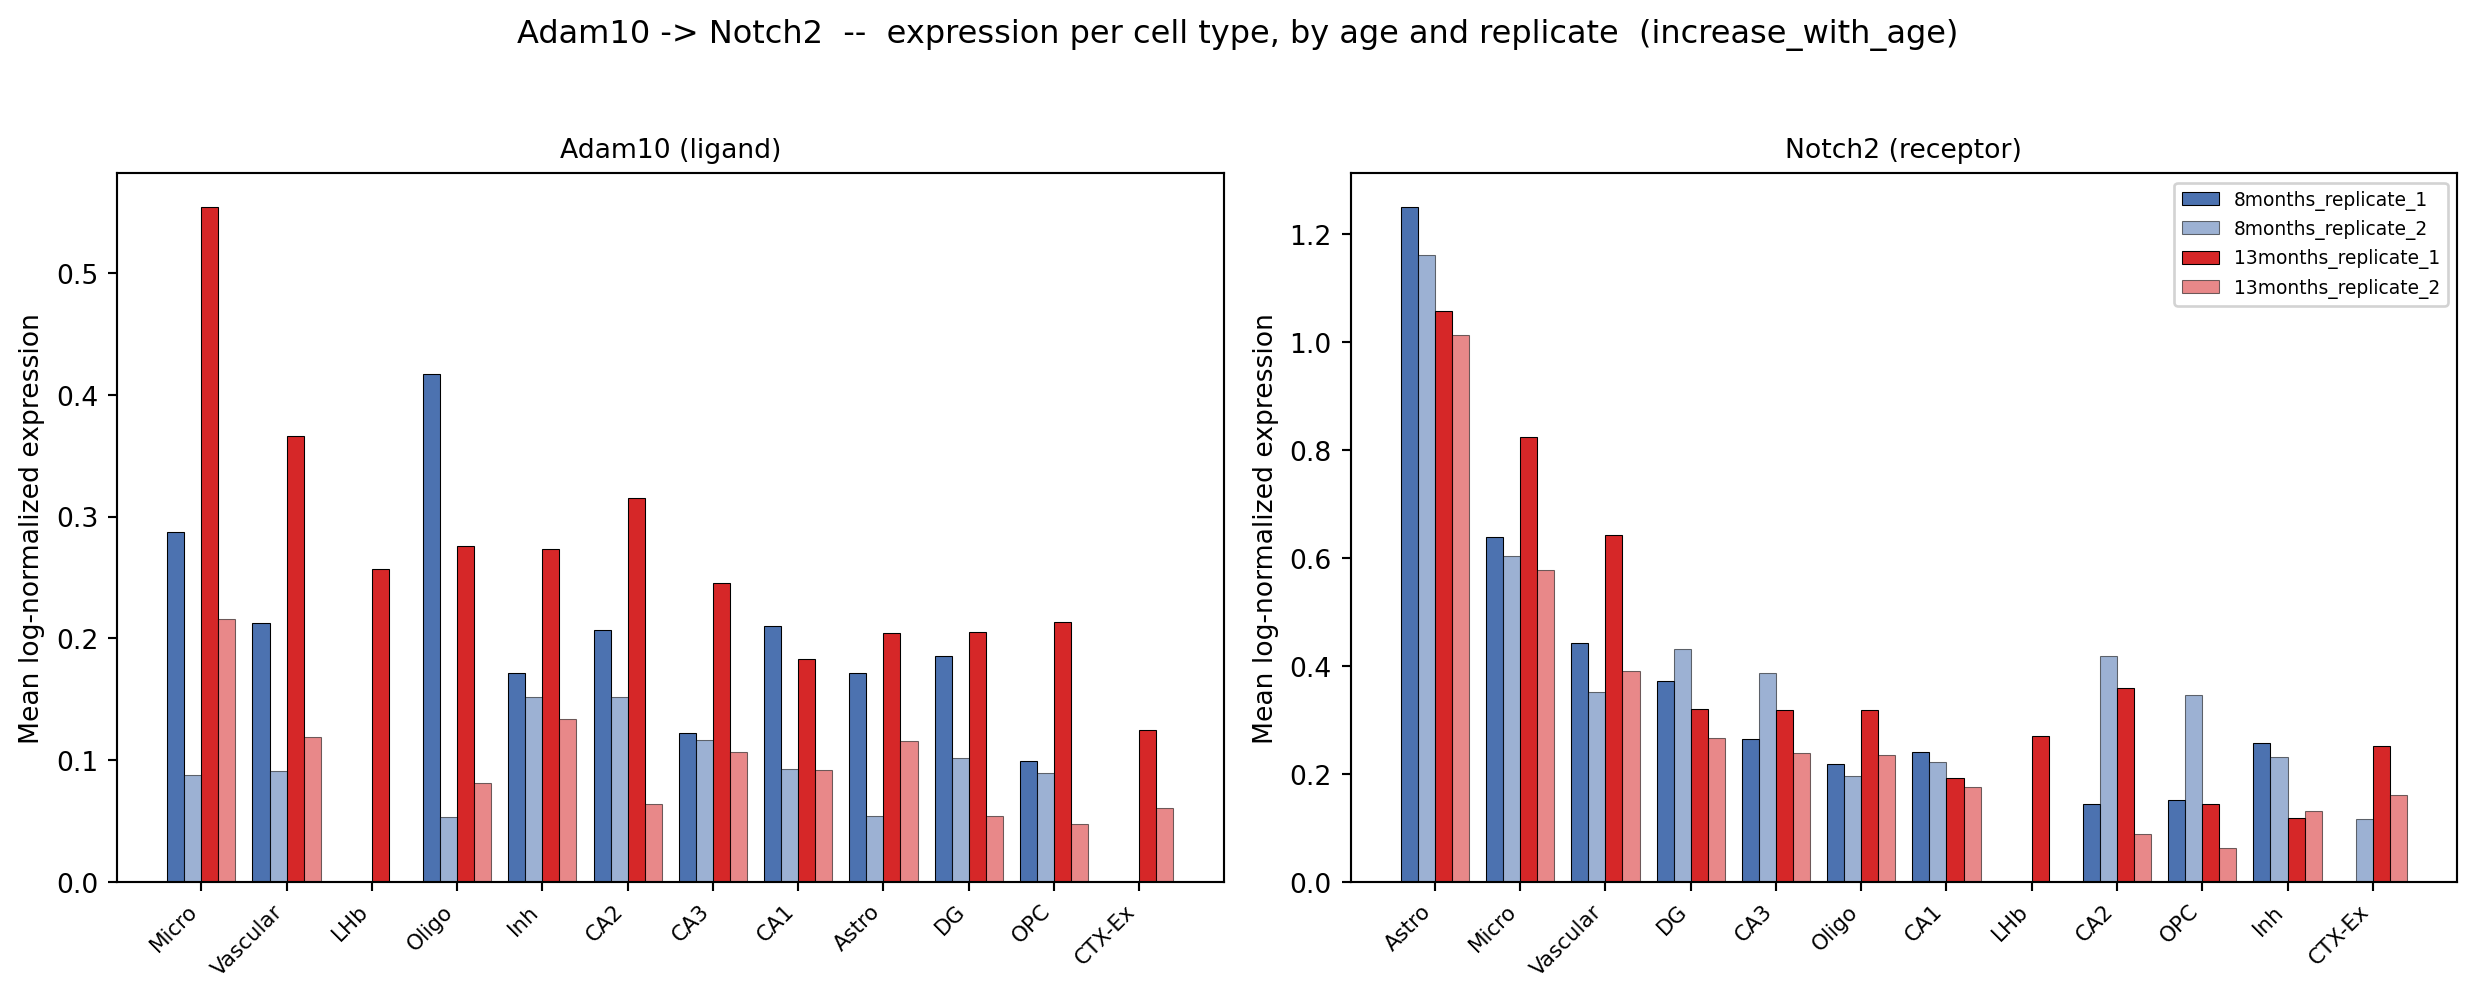

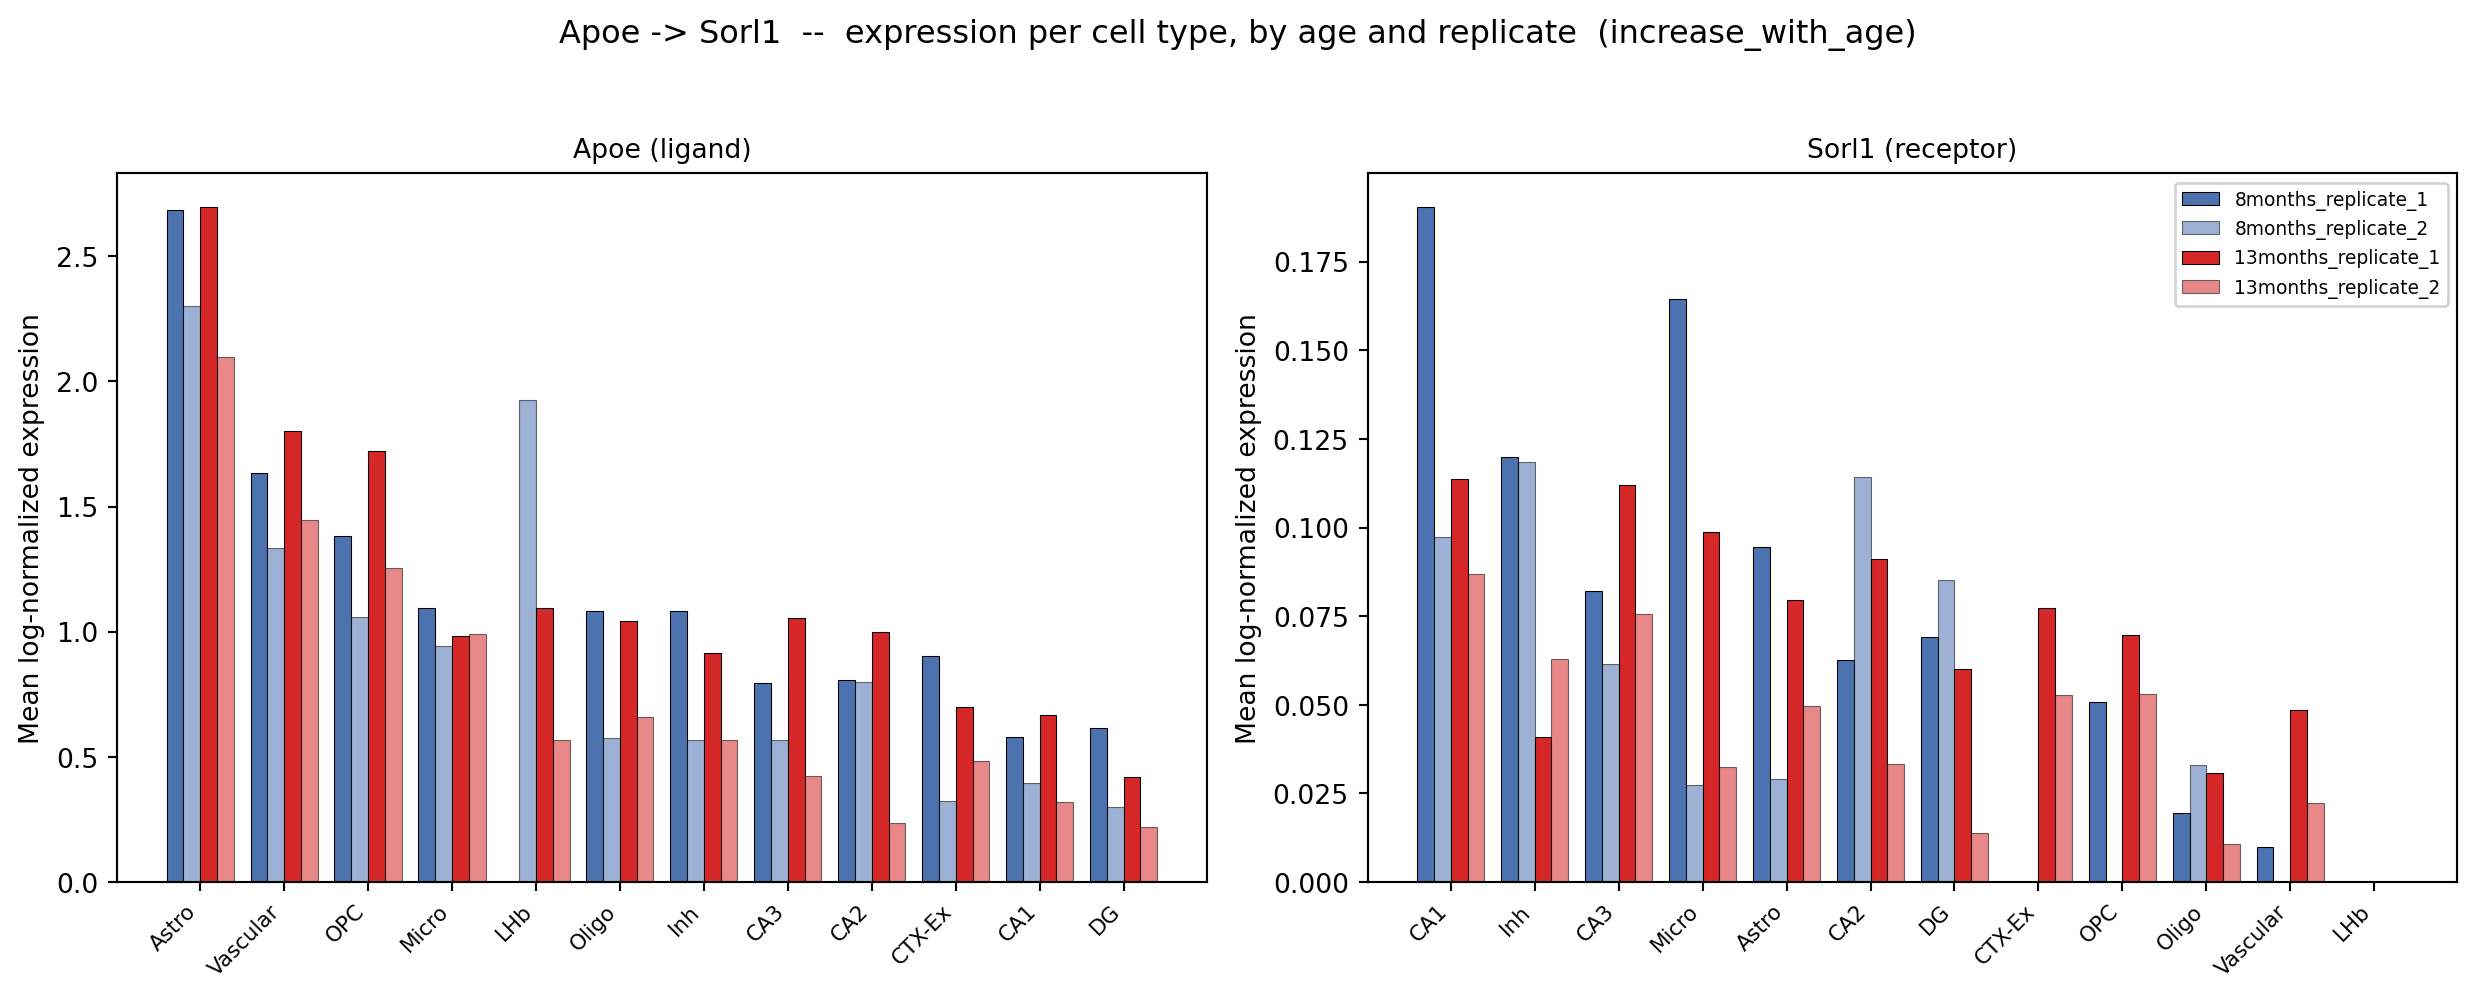

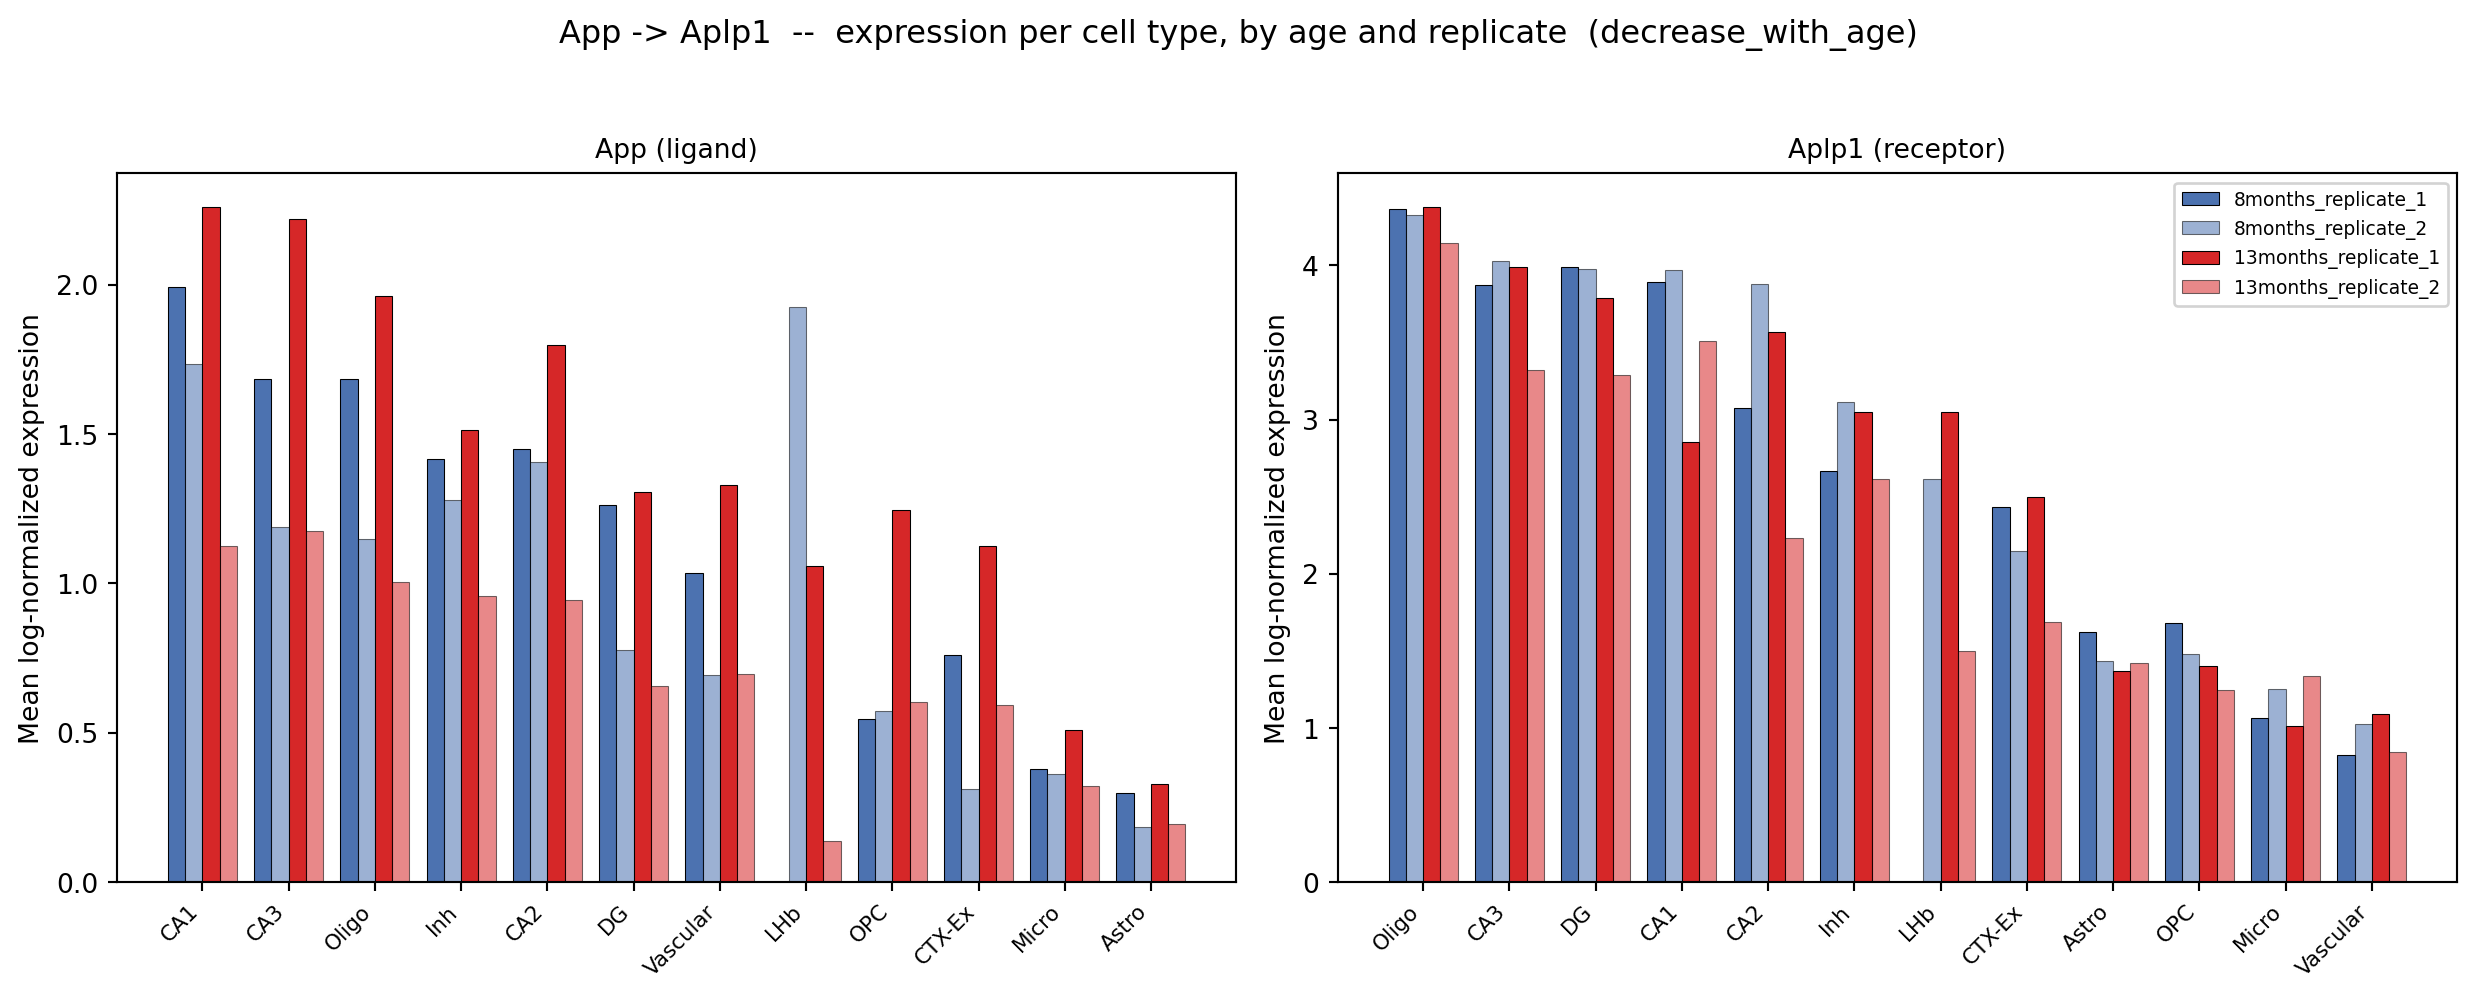

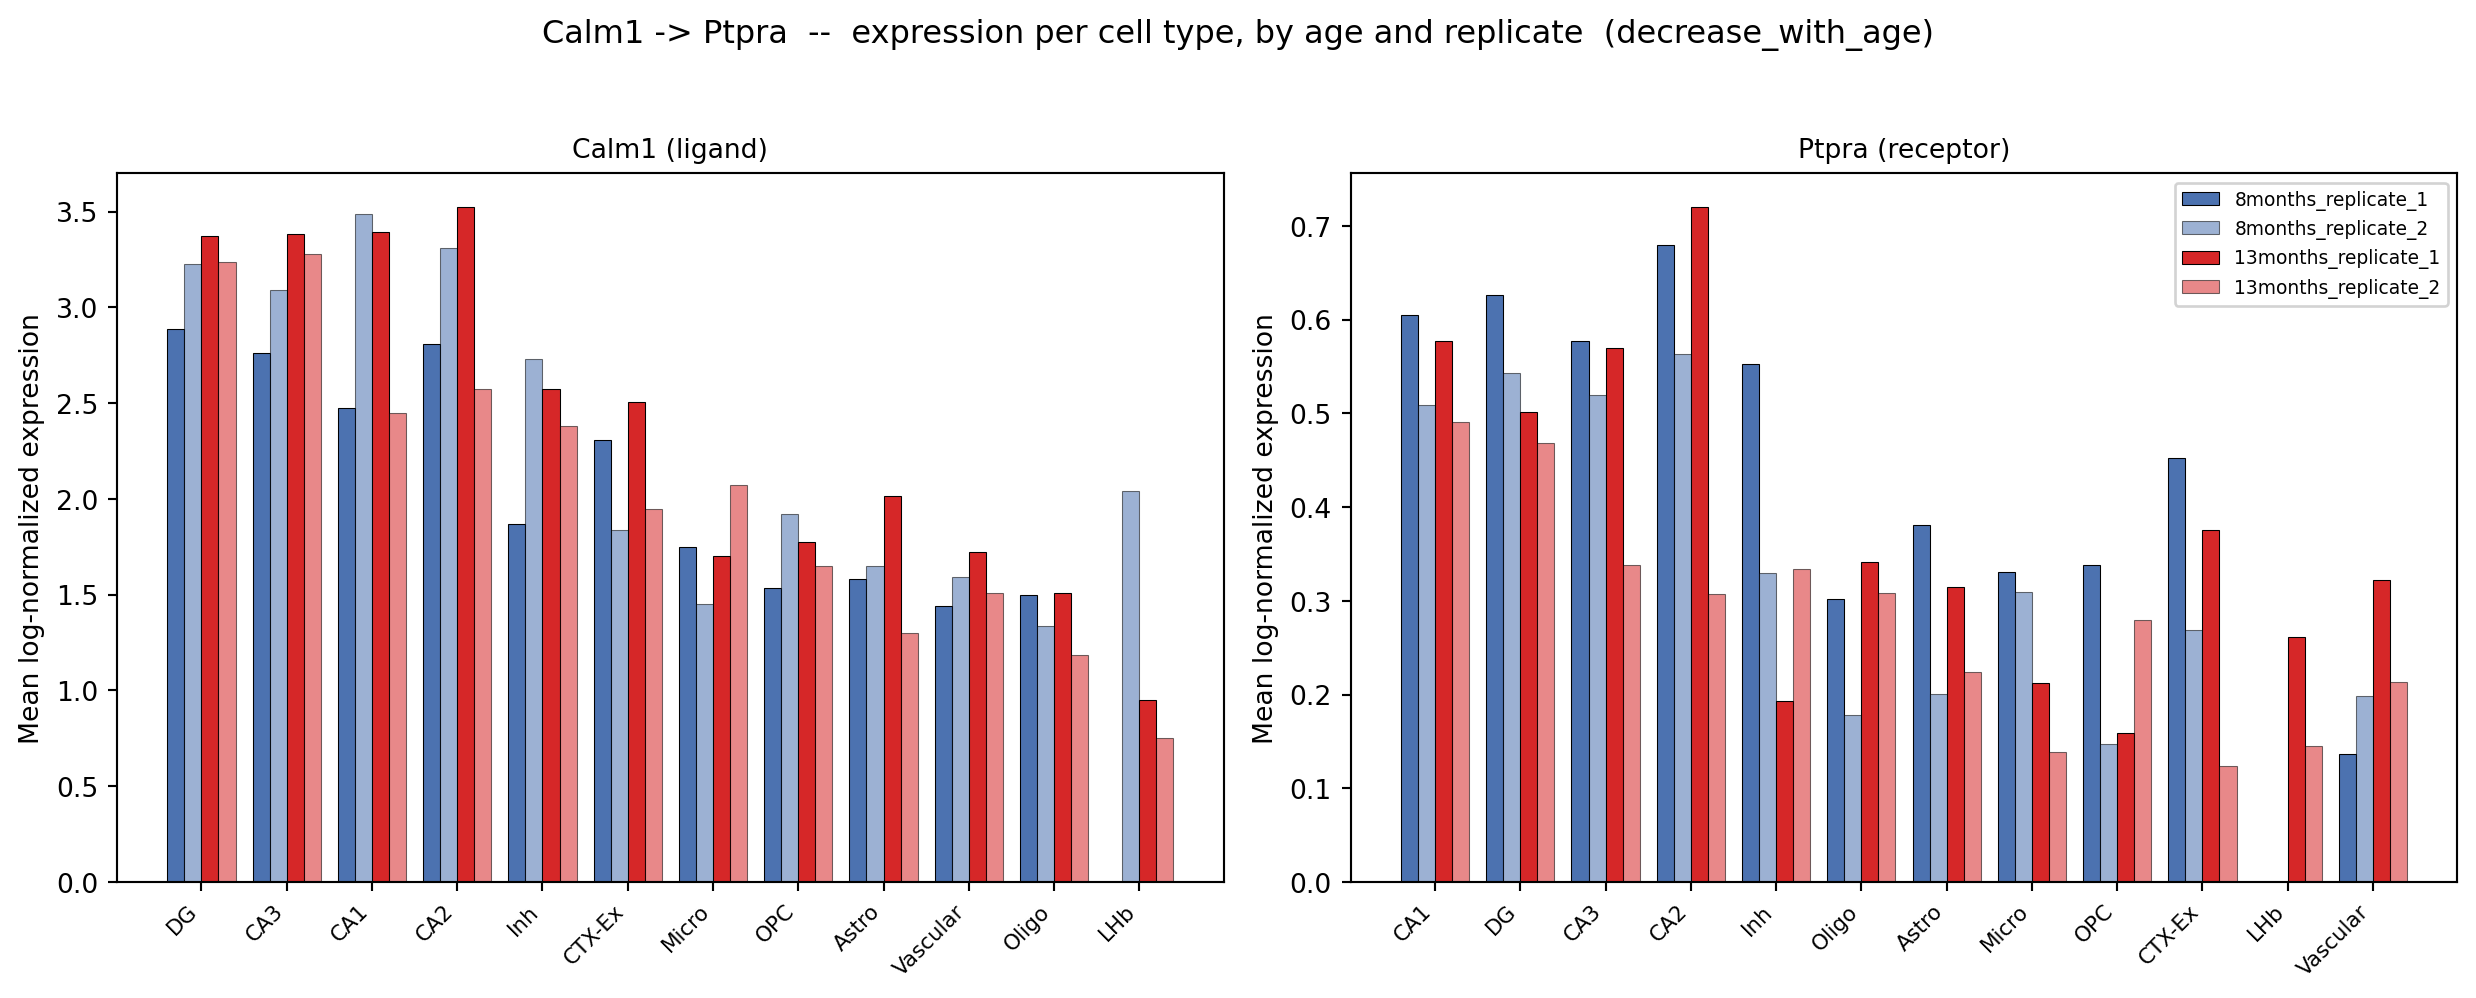

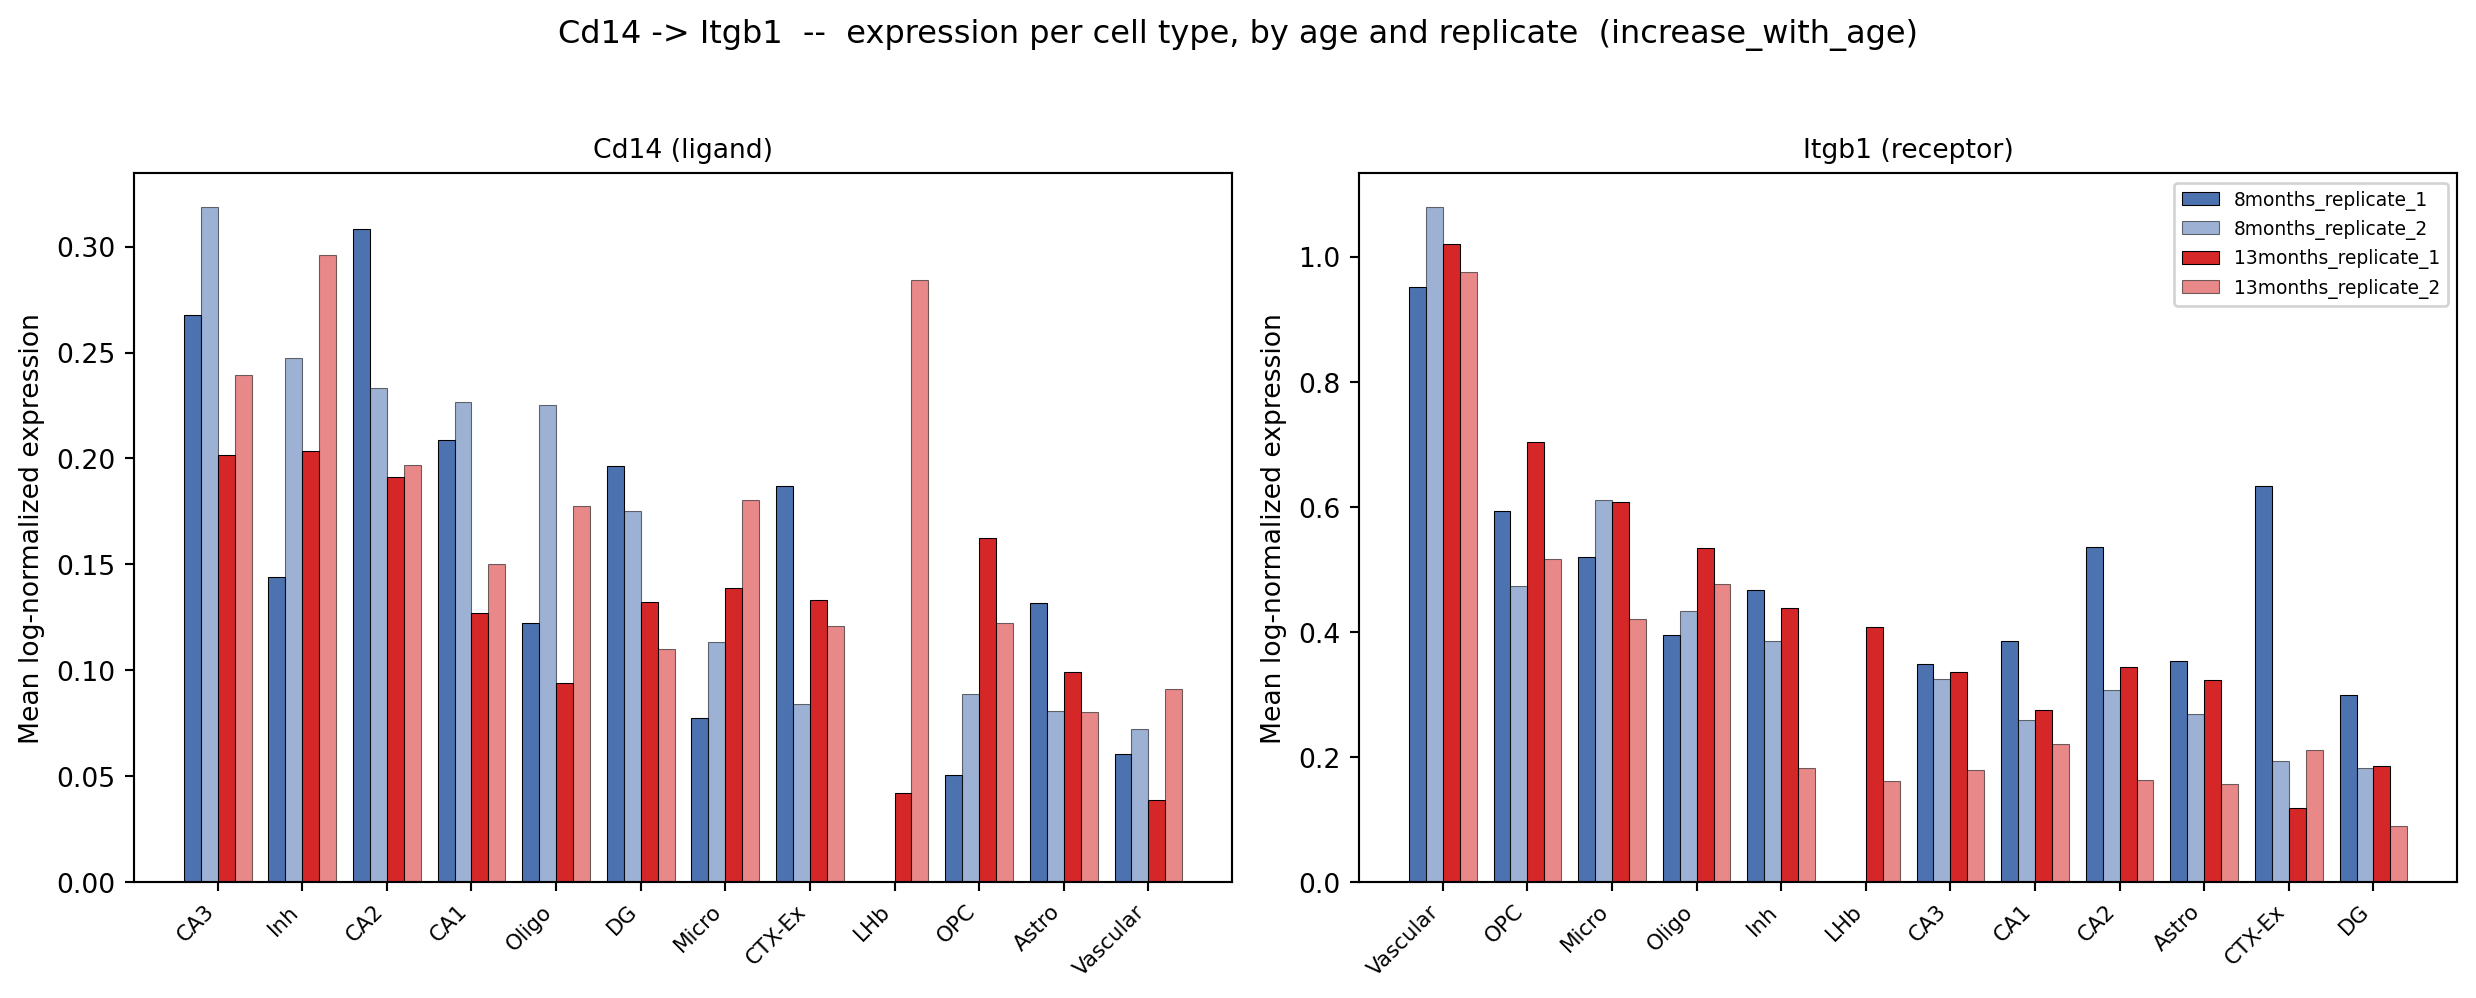

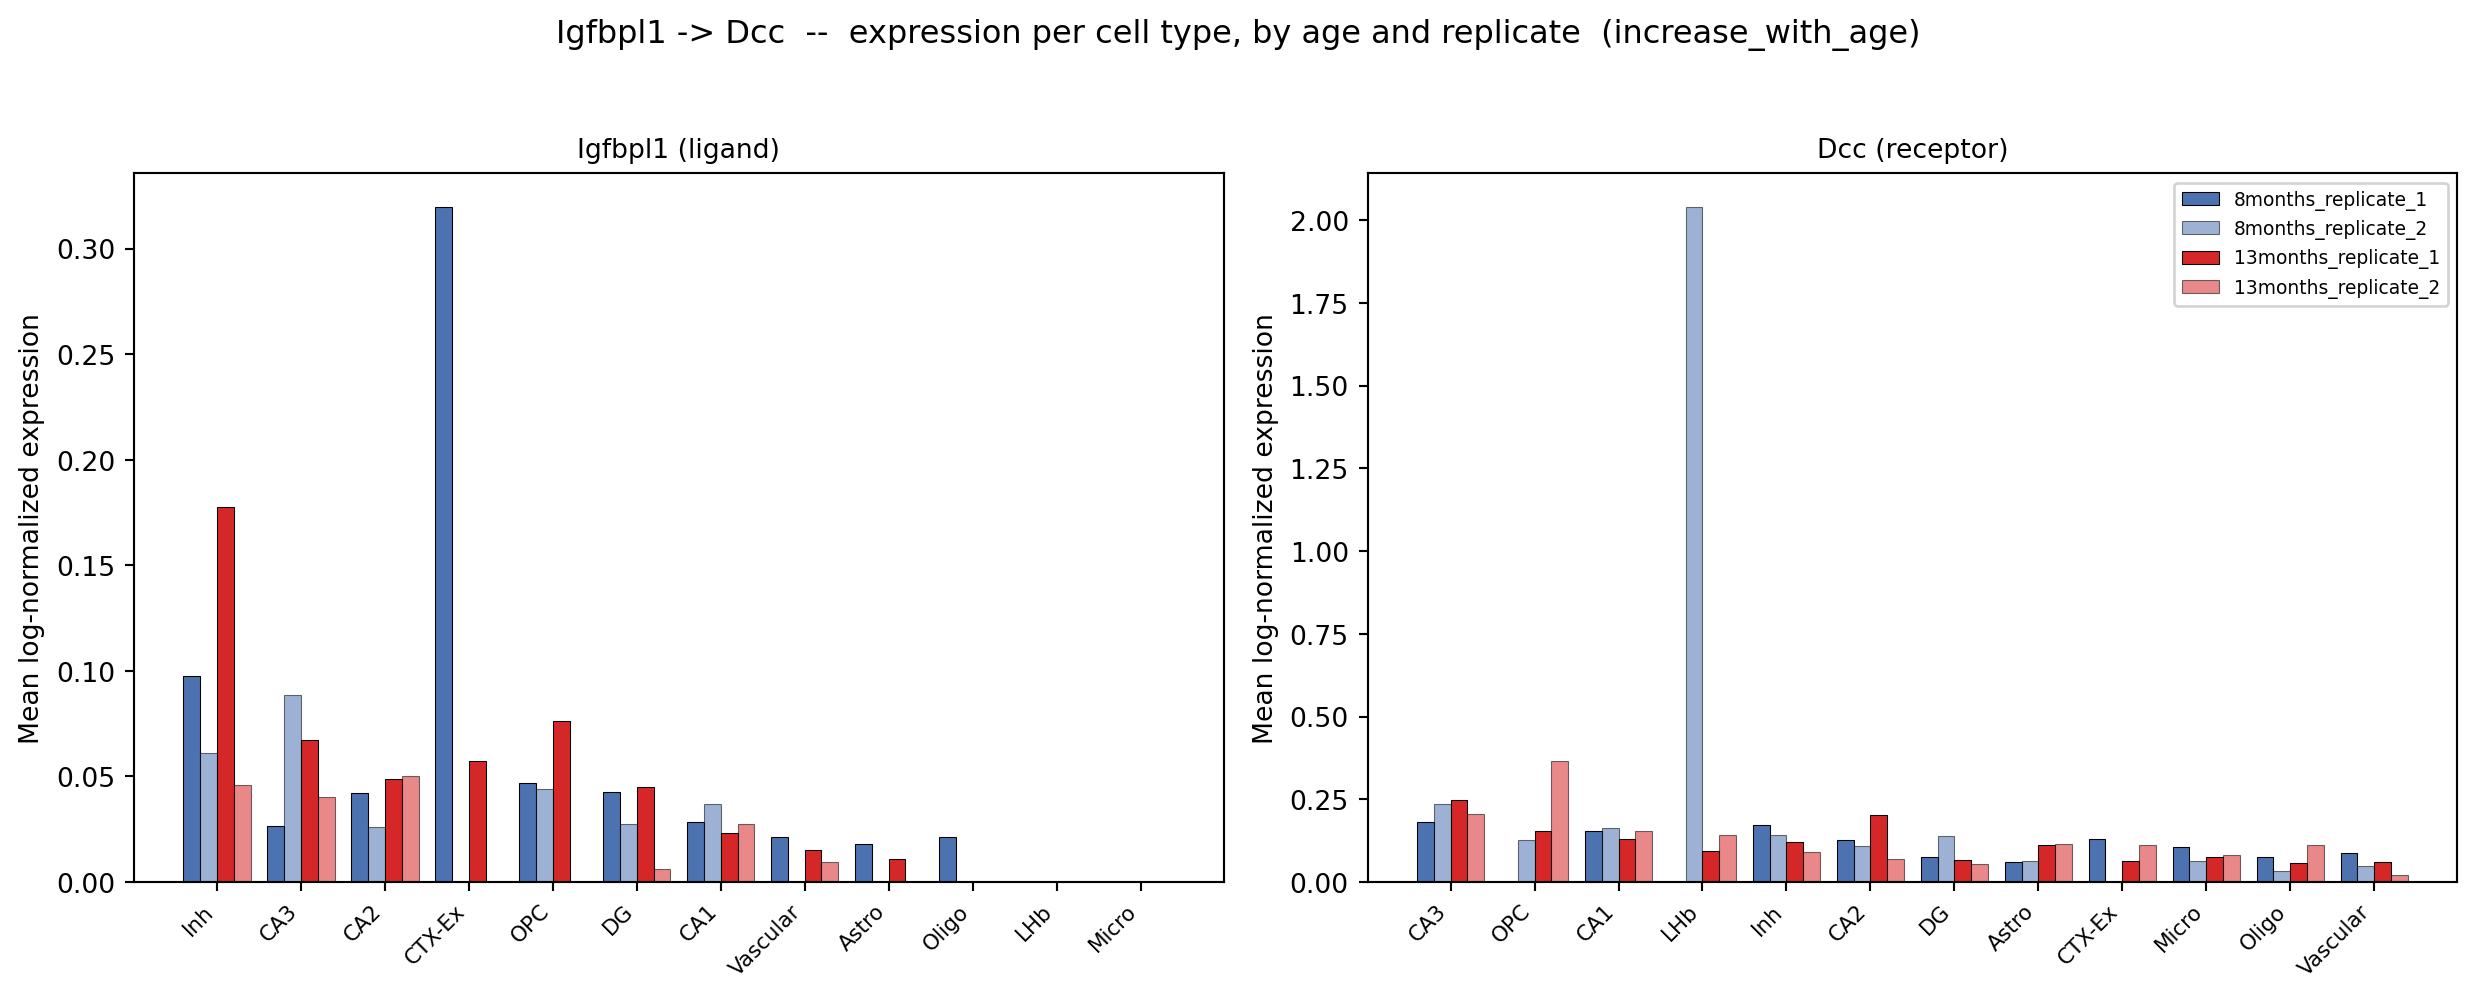

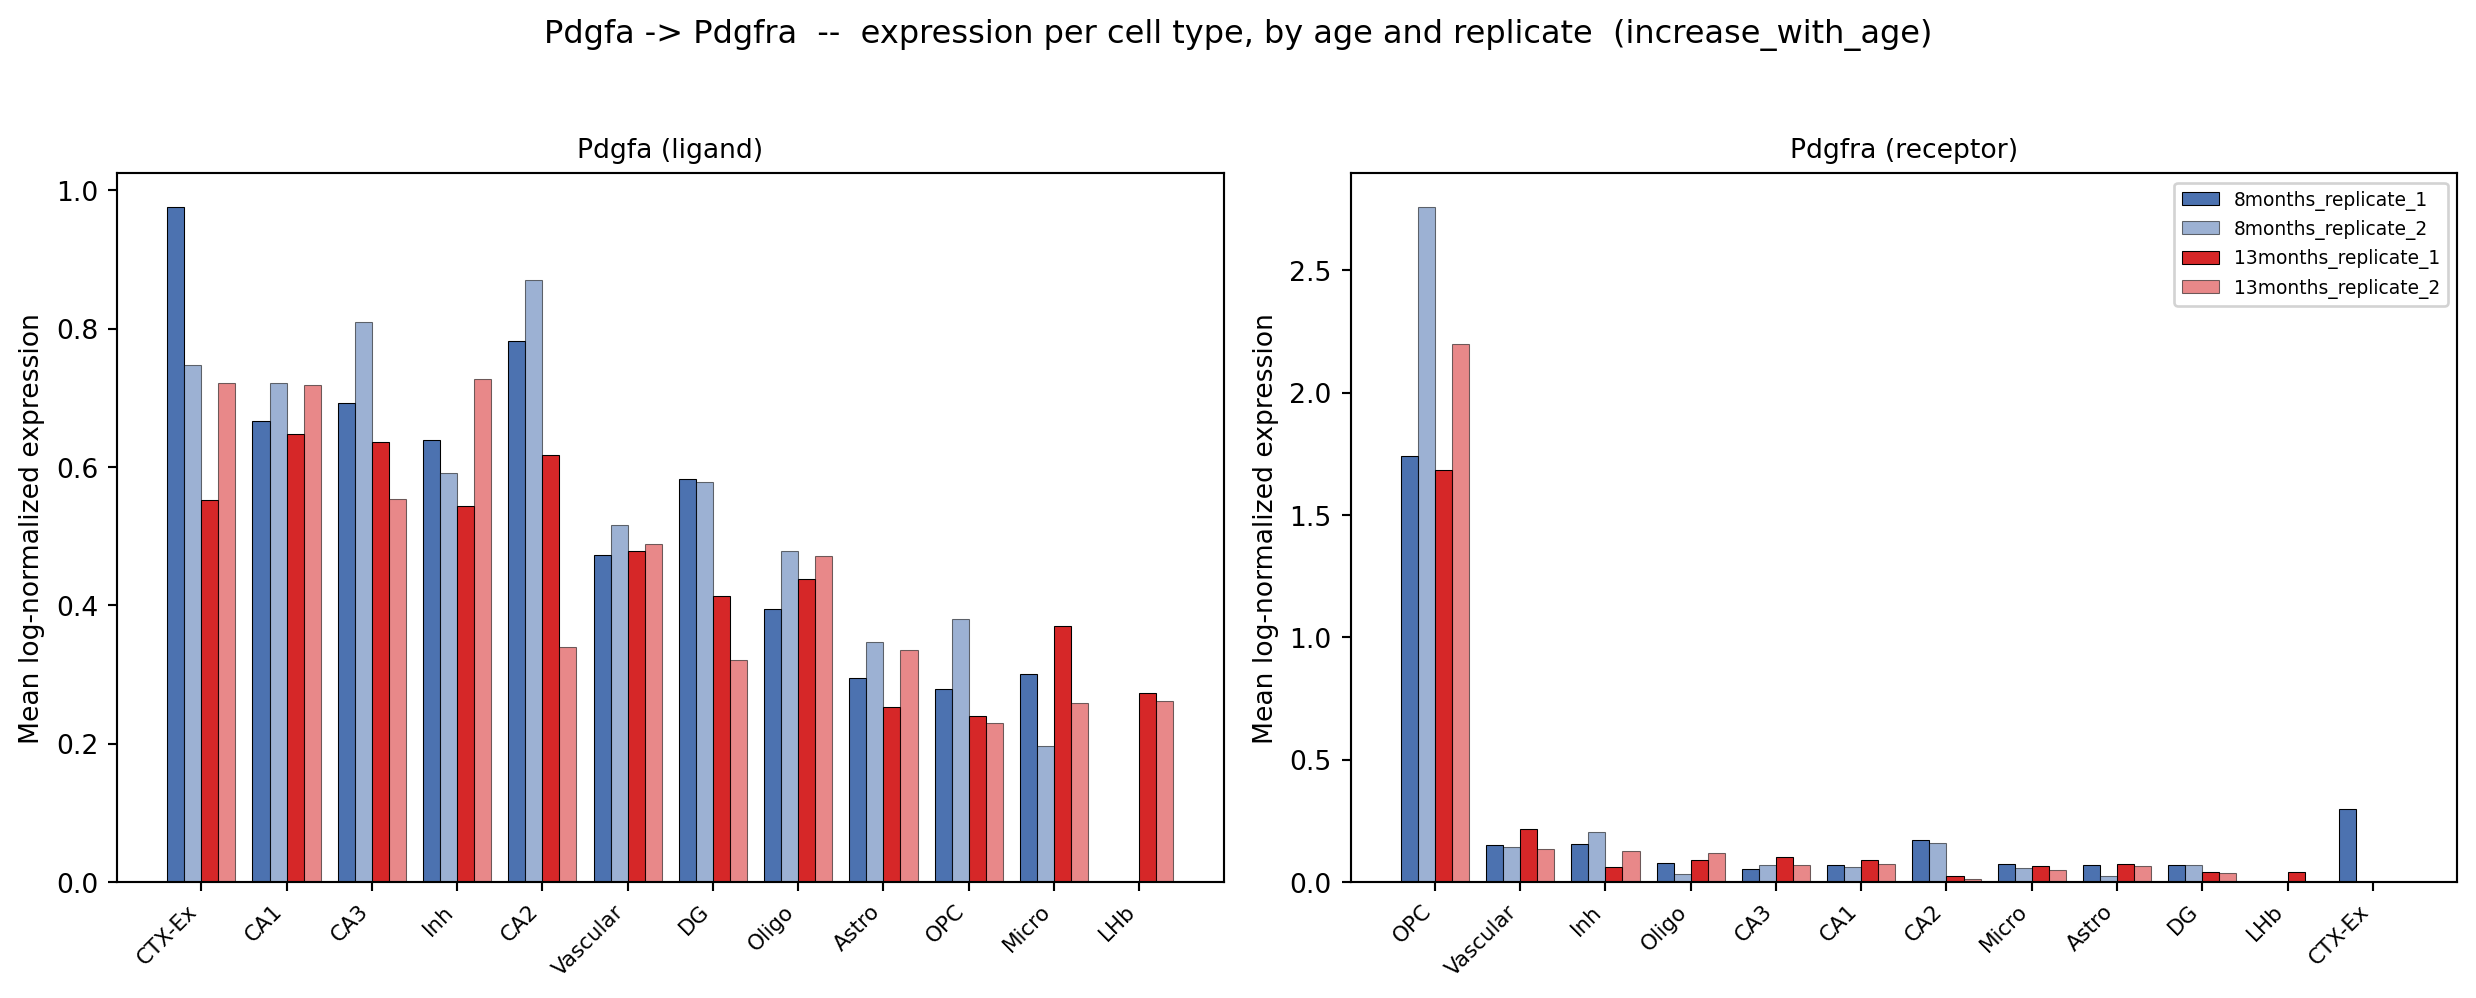

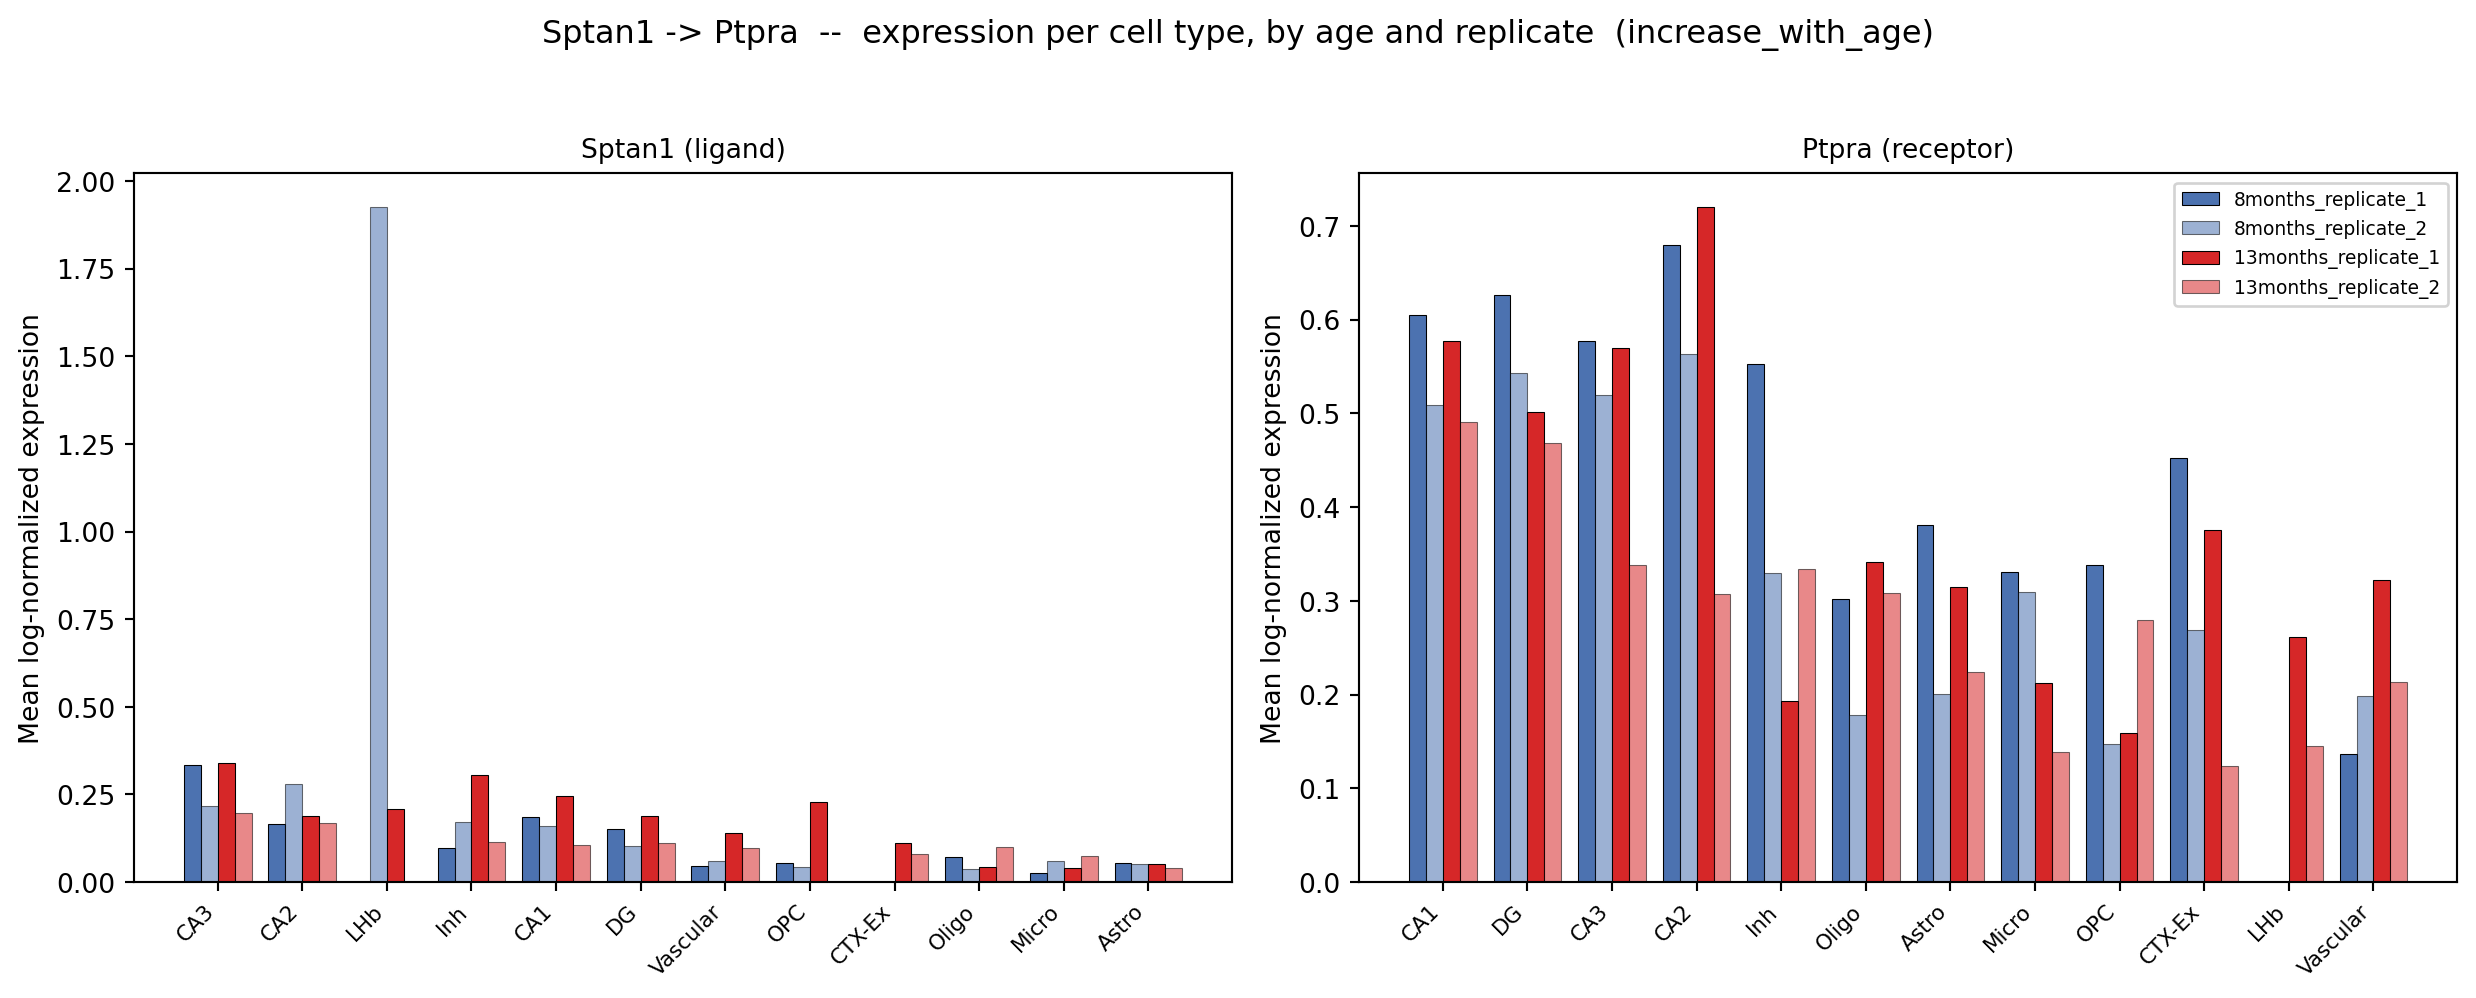

In [8]:
def complex_expression(adata_obj, complex_str):
    """Mean log-normalized expression across a complex's subunit genes (genes joined by '_', if
    any) -- same pattern as 09's complex_expression(), generalized to take an AnnData explicitly
    since this notebook has both the full combined `adata` and per-section subsets in `per_sample`."""
    genes_present = [g for g in str(complex_str).split("_") if g in adata_obj.var_names]
    if len(genes_present) == 0:
        return None
    vals = adata_obj[:, genes_present].X
    vals = np.asarray(vals.todense()) if hasattr(vals, "todense") else np.asarray(vals)
    return vals.mean(axis=1)

celltype_col = "celltype_merged" if "celltype_merged" in adata.obs.columns else "top_level_cell_type"

non_intermixed_pairs = hits_per_group[hits_per_group["trustworthy_shift"]].index.tolist()
print(f"{len(non_intermixed_pairs)} non-intermixed pair(s): {non_intermixed_pairs}")

pair_lookup = all_scores.drop_duplicates("pair_label").set_index("pair_label")[["ligand", "receptor"]]

# section order: young replicates, then old (not alphabetical)
replicate_vals = sorted(adata.obs[replicate_col].astype(str).unique())
section_order = [f"{age}_{rep}" for age in (young_age, old_age) for rep in replicate_vals]
section_order = [s for s in section_order if s in set(adata.obs[sample_col])]
age_for_section = adata.obs.drop_duplicates(sample_col).set_index(sample_col)[age_col].to_dict()

for pair_label in non_intermixed_pairs:
    ligand_gene = pair_lookup.loc[pair_label, "ligand"]
    receptor_gene = pair_lookup.loc[pair_label, "receptor"]

    ligand_expr = complex_expression(adata, ligand_gene)
    receptor_expr = complex_expression(adata, receptor_gene)
    if ligand_expr is None or receptor_expr is None:
        print(f"Skipping {pair_label}: '{ligand_gene}'/'{receptor_gene}' not found in adata.var_names")
        continue

    df = pd.DataFrame({
        celltype_col: adata.obs[celltype_col].values,
        sample_col: adata.obs[sample_col].values,
        "ligand": ligand_expr,
        "receptor": receptor_expr,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, gene_role, gene_name in [(axes[0], "ligand", ligand_gene), (axes[1], "receptor", receptor_gene)]:
        by_type_overall = df.groupby(celltype_col, observed=True)[gene_role].mean().sort_values(ascending=False)
        celltypes_order = by_type_overall.index.tolist()

        by_type_section = (
            df.groupby([celltype_col, sample_col], observed=True)[gene_role]
            .mean()
            .unstack(sample_col)
            .reindex(index=celltypes_order, columns=section_order)
        )

        x = np.arange(len(celltypes_order))
        n_sections = len(section_order)
        bar_width = 0.8 / n_sections

        for i, section in enumerate(section_order):
            offset = (i - (n_sections - 1) / 2) * bar_width
            age_val = age_for_section[section]
            is_rep2 = not section.endswith(replicate_vals[0])  # 2nd+ replicate drawn lighter
            ax.bar(
                x + offset, by_type_section[section].to_numpy(), width=bar_width,
                color=colors.get(age_val, "#999999"), alpha=0.55 if is_rep2 else 1.0,
                edgecolor="black", linewidth=0.4, label=section,
            )

        ax.set_xticks(x)
        ax.set_xticklabels(celltypes_order, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("Mean log-normalized expression")
        ax.set_title(f"{gene_name} ({gene_role})", fontsize=10)

    axes[1].legend(fontsize=7, loc="upper right", framealpha=0.85)
    plt.suptitle(f"{pair_label}  --  expression per cell type, by age and replicate  "
                 f"({hits_per_group.loc[pair_label, 'shift_direction']})", y=1.03)
    plt.tight_layout()
    plt.show()

## Save results

In [9]:
all_scores.to_csv(f"{out_dir}/bivariate_morans_by_sample.csv", index=False)
hits_per_group.to_csv(f"{out_dir}/bivariate_morans_age_classification.csv")
shift_df.to_csv(f"{out_dir}/bivariate_morans_age_shift.csv", index=False)
print(f"Saved {out_dir}/bivariate_morans_by_sample.csv, "
      f"{out_dir}/bivariate_morans_age_classification.csv, and "
      f"{out_dir}/bivariate_morans_age_shift.csv")

Saved output/10_STARmapPLUS_BivariateMoransI_AgeComparison/bivariate_morans_by_sample.csv, output/10_STARmapPLUS_BivariateMoransI_AgeComparison/bivariate_morans_age_classification.csv, and output/10_STARmapPLUS_BivariateMoransI_AgeComparison/bivariate_morans_age_shift.csv


## Null check: random control gene pairs

Compares each LR pair with random non-LR gene pairs scored with the same per-section graph and settings:

1. Is the LR score higher than for random genes with similar detection?
2. Do random pairs also shift between 8 and 13 months (section-level offset)?

Controls are matched on detection rate: genes are split into `n_detection_bins` (20) quantile bins, and for each LR pair `n_controls_per_pair` (500) pairs are drawn from the ligand's and receptor's bins. LR genes are excluded from the pool.

In [10]:
# ---- EDIT ----
n_controls_per_pair = 500   # matched random pairs per LR pair -> smallest possible empirical p = 1/501
n_detection_bins    = 20    # quantile bins of detection rate used for matching
control_seed        = 2024

rng = np.random.default_rng(control_seed)

# detection rate of every gene across all sections
X_all = adata.X
detection = pd.Series(np.asarray((X_all > 0).mean(axis=0)).ravel(), index=adata.var_names)

def complex_genes(complex_str):
    return [g for g in str(complex_str).split("_") if g in detection.index]

lr_gene_set = {g for lig, rec in interactions for comp in (lig, rec) for g in complex_genes(comp)}
pool = detection[(~detection.index.isin(lr_gene_set)) & (detection > 0)]

bin_edges = np.unique(np.quantile(pool.values, np.linspace(0, 1, n_detection_bins + 1)))
def detection_bin(v):
    return int(np.clip(np.searchsorted(bin_edges, v, side="right") - 1, 0, len(bin_edges) - 2))

pool_bin = pool.apply(detection_bin)

control_rows = []
for lig, rec in interactions:
    bin_l = detection_bin(detection[complex_genes(lig)].mean())
    bin_r = detection_bin(detection[complex_genes(rec)].mean())
    cand_l = pool_bin.index[pool_bin == bin_l].to_numpy()
    cand_r = pool_bin.index[pool_bin == bin_r].to_numpy()
    for _ in range(n_controls_per_pair):
        a = rng.choice(cand_l)
        b = rng.choice(cand_r)
        while b == a:
            b = rng.choice(cand_r)
        control_rows.append({"ligand": a, "receptor": b, "matched_to": f"{lig} -> {rec}",
                             "detection_bin_ligand": bin_l, "detection_bin_receptor": bin_r})

control_pairs = pd.DataFrame(control_rows).drop_duplicates(["ligand", "receptor", "matched_to"])
control_pairs["pair_label"] = control_pairs["ligand"] + " -> " + control_pairs["receptor"]
print(f"{len(control_pairs)} control pairs ({n_controls_per_pair} per LR pair, {len(interactions)} LR pairs), "
      f"drawn from {len(pool)} non-LR genes")
control_pairs.groupby("matched_to").size()

6421 control pairs (500 per LR pair, 13 LR pairs), drawn from 2742 non-LR genes


matched_to
Adam10 -> Notch2    493
Apoe -> Sorl1       494
App -> Aplp1        491
Bsg -> Slc16a7      493
Calm1 -> Ptpra      498
Cd14 -> Itgb1       494
Cxcl12 -> Itgb1     496
Efnb2 -> Grm5       498
Fgfr3 -> Epha4      493
Igfbpl1 -> Dcc      495
Pdgfa -> Pdgfra     497
Ptn -> Ptprs        490
Sptan1 -> Ptpra     489
dtype: int64

Each section reuses its graph from above; only the global score is computed (`local_name=None`).

In [11]:
control_interactions = list(dict.fromkeys(zip(control_pairs["ligand"], control_pairs["receptor"])))

def global_table(res):
    """bivariate() returns an AnnData (global stats in .var) or a DataFrame, depending on local_name."""
    g = res.copy() if isinstance(res, pd.DataFrame) else res.var.copy()
    g = g.reset_index().rename(columns={"index": "pair_id"})
    if not {"ligand", "receptor"}.issubset(g.columns):
        split = g["pair_id"].astype(str).str.split("^", n=1, expand=True, regex=False)
        g["ligand"], g["receptor"] = split[0], split[1]
    return g

control_records = []
for sample_id, res in per_sample.items():
    adata_s = res["adata"]   # already carries this section's spatial_connectivities
    ctrl_res = li.mt.bivariate(
        adata_s,
        resource_name=None,
        interactions=control_interactions,
        global_name="morans",
        local_name=None,
        connectivity_key="spatial_connectivities",
        n_perms=10,      # liana's own permutation p-values aren't used here -- significance comes from the matched controls
        mask_negatives=False,
        nz_prop=0,
        seed=1337,
        use_raw=False,
        verbose=False,
    )
    g = global_table(ctrl_res)
    g["sample"] = sample_id
    g["age"] = res["age"]
    control_records.append(g)
    print(f"{sample_id}: {len(g)} control pairs scored")

control_scores = pd.concat(control_records, ignore_index=True)
ctrl_score_col = next(c for c in control_scores.columns if "morans" in c.lower() and "pval" not in c.lower())
control_scores["pair_label"] = control_scores["ligand"].astype(str) + " -> " + control_scores["receptor"].astype(str)

# attach which LR pair each control was matched to (a control pair can serve several LR pairs)
control_long = control_scores.merge(control_pairs[["pair_label", "matched_to"]], on="pair_label", how="inner")

13months_replicate_1: 6408 control pairs scored


13months_replicate_2: 6408 control pairs scored


8months_replicate_1: 6408 control pairs scored


8months_replicate_2: 6408 control pairs scored


### Section-level offset

Control scores per section. If random pairs are also higher at 13 months, LR "increases with age" are partly a section effect.

              sample      age  ctrl_mean  ctrl_sd  ctrl_q025  ctrl_q975    n
13months_replicate_1 13months     0.0044   0.0130    -0.0140     0.0365 6408
13months_replicate_2 13months     0.0038   0.0114    -0.0126     0.0299 6408
 8months_replicate_1  8months     0.0057   0.0184    -0.0180     0.0530 6408
 8months_replicate_2  8months     0.0048   0.0150    -0.0151     0.0436 6408

Mean control Moran's I: 8months = 0.0053, 13months = 0.0041 (shift -0.0012)
Mean LR Moran's I:      8months = 0.0024, 13months = 0.0031 (shift +0.0008)


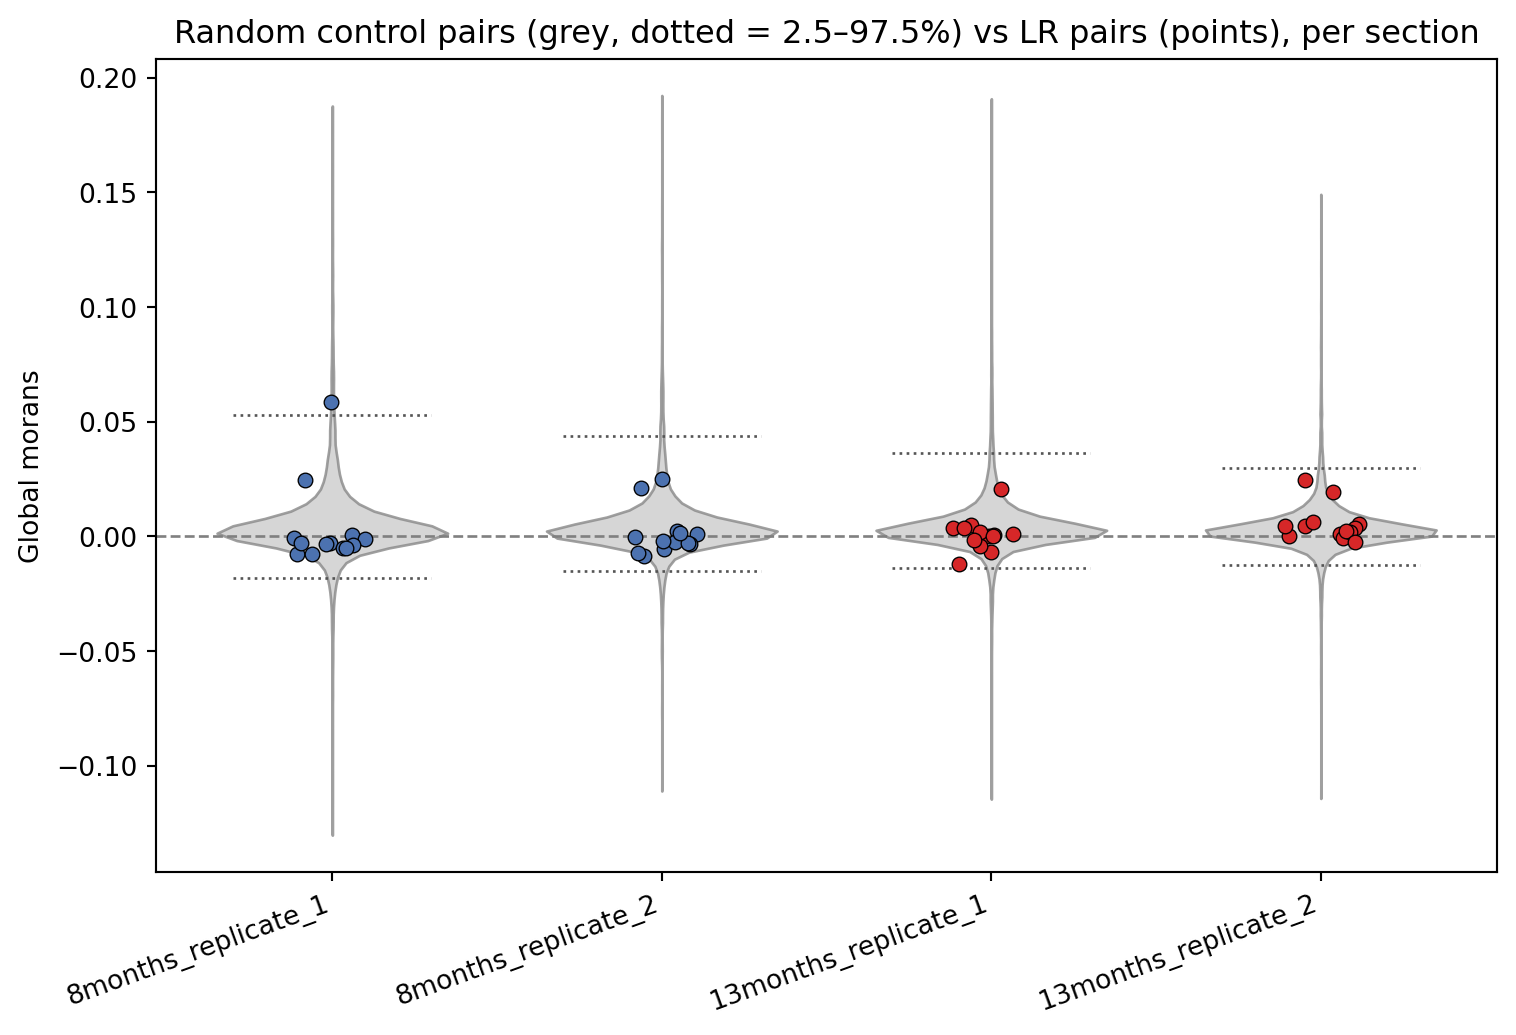

In [12]:
null_by_section = (
    control_scores.groupby(["sample", "age"], observed=True)[ctrl_score_col]
    .agg(ctrl_mean="mean", ctrl_sd="std",
         ctrl_q025=lambda s: s.quantile(0.025), ctrl_q975=lambda s: s.quantile(0.975), n="size")
    .reset_index()
)
print(null_by_section.round(4).to_string(index=False))

ctrl_age_means = null_by_section.groupby("age")["ctrl_mean"].mean()
lr_age_means = all_scores.groupby("age")[score_col].mean()
print(f"\nMean control Moran's I: {young_age} = {ctrl_age_means[young_age]:.4f}, {old_age} = {ctrl_age_means[old_age]:.4f} "
      f"(shift {ctrl_age_means[old_age] - ctrl_age_means[young_age]:+.4f})")
print(f"Mean LR Moran's I:      {young_age} = {lr_age_means[young_age]:.4f}, {old_age} = {lr_age_means[old_age]:.4f} "
      f"(shift {lr_age_means[old_age] - lr_age_means[young_age]:+.4f})")

# controls shown as violins, LR pairs overlaid as points
section_order_ctrl = sorted(per_sample.keys(), key=lambda s: (extract_months(per_sample[s]["age"]), s))
fig, ax = plt.subplots(figsize=(8, 5.5))
ctrl_vals = [control_scores.loc[control_scores["sample"] == s, ctrl_score_col].to_numpy() for s in section_order_ctrl]
parts = ax.violinplot(ctrl_vals, positions=range(len(section_order_ctrl)), showextrema=False, widths=0.7)
for b in parts["bodies"]:
    b.set_facecolor("#cccccc"); b.set_edgecolor("#888888"); b.set_alpha(0.8)

age_colors = {young_age: "#4c72b0", old_age: "#d62728"}
for i, s in enumerate(section_order_ctrl):
    lr_s = all_scores[all_scores["sample"] == s]
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(lr_s)), lr_s[score_col],
               color=age_colors.get(per_sample[s]["age"], "black"), s=30, edgecolors="black", linewidths=0.5, zorder=3)
    ax.hlines(null_by_section.loc[null_by_section["sample"] == s, ["ctrl_q025", "ctrl_q975"]].to_numpy().ravel(),
              i - 0.3, i + 0.3, color="#555555", linestyles=":", linewidth=1)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(range(len(section_order_ctrl)))
ax.set_xticklabels(section_order_ctrl, rotation=20, ha="right")
ax.set_ylabel(f"Global {score_col}")
ax.set_title("Random control pairs (grey, dotted = 2.5–97.5%) vs LR pairs (points), per section")
plt.tight_layout()
plt.savefig(f"{out_dir}/control_vs_lr_morans_by_section.png", dpi=200, bbox_inches="tight")
plt.show()

### Are the LR pairs above their matched controls?

One-sided: is the LR score **higher** than its matched controls?

1. **Per section:** `p = (1 + #controls >= LR score) / (n_controls + 1)`; z-score for effect size.
2. **Across sections:** Stouffer combination of the 4 sections (and of the 2 sections per age).
3. **Across pairs:** BH correction; `beyond_chance` = `p_adj < 0.05`.

In [13]:
from scipy.stats import norm

def bh_adjust(p):
    """Benjamini-Hochberg adjusted p-values (same as R's p.adjust(method = "BH"))."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(ranked, 0, 1)
    return out

def stouffer(pvals):
    """One-sided p-values -> one combined one-sided p (equal weights)."""
    pvals = np.clip(np.asarray(pvals, dtype=float), 1e-300, 1 - 1e-16)
    return norm.sf(norm.isf(pvals).sum() / np.sqrt(len(pvals)))

matched_null = (
    control_long.groupby(["matched_to", "sample"], observed=True)[ctrl_score_col]
    .agg(list)
    .rename("control_values")
    .reset_index()
    .rename(columns={"matched_to": "pair_label"})
)

lr_vs_controls = all_scores[["pair_label", "sample", "age", score_col]].merge(
    matched_null, on=["pair_label", "sample"], how="left"
)

def section_stats(row):
    ctrl = np.asarray(row["control_values"], dtype=float)
    x = row[score_col]
    return pd.Series({
        "n_controls": len(ctrl),
        "z_vs_matched": (x - ctrl.mean()) / ctrl.std(ddof=1),
        "p_empirical": (1 + np.sum(ctrl >= x)) / (len(ctrl) + 1),
    })

lr_vs_controls = pd.concat([lr_vs_controls, lr_vs_controls.apply(section_stats, axis=1)], axis=1)
lr_vs_controls = lr_vs_controls.drop(columns="control_values")

# per-section p-values side by side
p_wide = lr_vs_controls.pivot_table(index="pair_label", columns="sample", values="p_empirical")
p_wide = p_wide[section_order_ctrl].add_prefix("p_")

summary_vs_controls = (
    lr_vs_controls.groupby("pair_label")
    .agg(mean_score=(score_col, "mean"), mean_z=("z_vs_matched", "mean"))
    .join(p_wide)
)
summary_vs_controls["p_combined"] = lr_vs_controls.groupby("pair_label")["p_empirical"].apply(stouffer)
for age_label, tag in [(young_age, "young"), (old_age, "old")]:
    summary_vs_controls[f"p_combined_{tag}"] = (
        lr_vs_controls[lr_vs_controls["age"] == age_label].groupby("pair_label")["p_empirical"].apply(stouffer)
    )
summary_vs_controls["p_adj"] = bh_adjust(summary_vs_controls["p_combined"])
summary_vs_controls["beyond_chance"] = summary_vs_controls["p_adj"] < 0.05
summary_vs_controls = summary_vs_controls.sort_values("p_combined")

print(f"{summary_vs_controls['beyond_chance'].sum()}/{len(summary_vs_controls)} LR pairs co-vary in space more than "
      f"detection-matched random pairs (Stouffer across {len(section_order_ctrl)} sections, BH p_adj < 0.05)")
summary_vs_controls.style.format({c: "{:.3g}" for c in summary_vs_controls.columns if c.startswith("p")}
                                 | {"mean_score": "{:.4f}", "mean_z": "{:.2f}"})

0/13 LR pairs co-vary in space more than detection-matched random pairs (Stouffer across 4 sections, BH p_adj < 0.05)


,mean_score,mean_z,p_8months_replicate_1,p_8months_replicate_2,p_13months_replicate_1,p_13months_replicate_2,p_combined,p_combined_young,p_combined_old,p_adj,beyond_chance
pair_label,,,,,,,,,,,
Calm1 -> Ptpra,0.0237,0.69,0.255,0.16,0.188,0.0982,0.0278,0.121,0.062,0.361,False
Efnb2 -> Grm5,0.0010,0.19,0.473,0.226,0.547,0.367,0.301,0.281,0.438,0.994,False
Igfbpl1 -> Dcc,0.0014,0.28,0.938,0.397,0.375,0.0343,0.332,0.816,0.0651,0.994,False
App -> Aplp1,0.0247,-0.02,0.234,0.516,0.795,0.376,0.464,0.314,0.64,0.994,False
Adam10 -> Notch2,0.0017,-0.09,0.749,0.698,0.306,0.334,0.551,0.8,0.254,0.994,False
Sptan1 -> Ptpra,0.0016,-0.13,0.686,0.543,0.384,0.498,0.558,0.662,0.416,0.994,False
Pdgfa -> Pdgfra,0.0008,-0.25,0.833,0.859,0.418,0.175,0.674,0.926,0.209,0.994,False
Apoe -> Sorl1,-0.0012,-0.73,0.893,0.972,0.628,0.275,0.925,0.987,0.424,0.994,False
Bsg -> Slc16a7,-0.0028,-0.58,0.806,0.8,0.743,0.765,0.938,0.886,0.835,0.994,False


In [14]:
control_pairs.to_csv(f"{out_dir}/control_pairs.csv", index=False)
control_scores.to_csv(f"{out_dir}/control_morans_by_sample.csv", index=False)
null_by_section.to_csv(f"{out_dir}/control_null_by_section.csv", index=False)
lr_vs_controls.to_csv(f"{out_dir}/lr_vs_controls_by_sample.csv", index=False)
summary_vs_controls.reset_index().to_csv(f"{out_dir}/lr_vs_controls_summary.csv", index=False)
print("Saved control-pair results to", out_dir)

Saved control-pair results to output/10_STARmapPLUS_BivariateMoransI_AgeComparison


## Notes

- Global Moran's I only; per-section objects are in `per_sample[<section>]["adata"]` / `["bivar_adata"]` for local follow-up.
- liana's own p-value only says ligand and receptor are not randomly scattered relative to each other. 
- The matched controls are random gene pairs, detected in a similar share of cells, in the same sections. They show how much co-variation you get from tissue structure and expression level.
- No LR pair scores above its controls. So the ligand and receptor of each pair are not more spatially linked than two random genes expressed like them. The co-variation we see comes from both genes being expressed in the same broad regions, not from anything specific to the ligand-receptor pairing.
- This does **not** show that the interactions don't happen. Global Moran's I averages over the whole hippocampus, so signalling restricted to a small region or a few cell types can be diluted, and sparsely detected genes give little power.
- In practice: STARmap PLUS confirms that these genes are expressed in overlapping regions, but it does not provide independent evidence for these specific LR interactions, and their age shifts here should not be used as validation.